# Event-Variance Decomposition of Implied Correlation: Macro Co-Jumps, Earnings Jumps and Theta-Weighted Dispersion

**Kenneth Anthony Wijaya** — Data Structures & Algorithms Capstone, Imperial College Business School

Pipeline: **data acquisition → cleaning → feature construction (implied/realised correlation, event-variance decomposition) → strategy → backtest → diagnostics.**

Data: **WRDS** (OptionMetrics options 1996-2025, CRSP membership and market caps, Compustat earnings dates) as the primary source; Federal Reserve FOMC calendars; FRED release dates and T-bill rate; Cboe indices for validation. The free-data route (DoltHub, Yahoo, SEC EDGAR) in 1.2-1.6 is kept as an independent cross-check for 2019-2025.

Design sample 1996-2012, held-out test 2013-01 to 2025-08 (see `docs/research_log.md`).

> Run top-to-bottom. Download cells cache to `data/raw/` and skip work already done, so re-running is cheap. Set `REFRESH = True` to force fresh downloads.

## 0. Setup

Install once (in a terminal or here):

```
pip install pandas numpy requests yfinance pyarrow matplotlib scipy statsmodels
```

Credentials are read from **environment variables** and are never written into this notebook:

* `FRED_API_KEY` — free key from https://fred.stlouisfed.org/docs/api/api_key.html
* `SEC_USER_AGENT` — SEC asks every automated client to identify itself as `"Name email"`.

On Windows (PowerShell), before launching Jupyter: `setx FRED_API_KEY "your_key"` then restart Jupyter.

In [1]:
import os, io, re, json, time, hashlib, datetime as dt
from pathlib import Path

import numpy as np
import pandas as pd
import requests

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)

# ---------------------------------------------------------------- paths
ROOT = Path.cwd()
RAW  = ROOT / "data" / "raw"
PROC = ROOT / "data" / "processed"
for p in (RAW, PROC, RAW / "cboe", RAW / "yahoo", RAW / "dolthub_vol", RAW / "dolthub_chain", RAW / "sec", RAW / "fred"):
    p.mkdir(parents=True, exist_ok=True)

# ---------------------------------------------------------------- study design (fixed BEFORE looking at results)
SAMPLE_START = "2019-01-01"   # DoltHub options history begins Feb-2019
PRICE_START  = "2018-06-01"   # extra price history so trailing windows exist at the first rebalance
SAMPLE_END   = "2026-10-16"   # last full trading day available when the snapshot was taken
DESIGN_END   = "2022-12-31"   # design / in-sample period ends; 2023-01-01 onward is held out
N_BASKET     = 50             # top-50 S&P 500 names by market cap (mirrors the Cboe COR basket)
PREFILTER_N  = 100            # liquidity pre-filter size used to limit share-count downloads
REFRESH      = False          # True -> ignore caches and re-download

# Research-log Amendment 1 (19 Oct 2026, before any results): WRDS is the primary source and fixes the study window.
# The 2019+ constants above now only govern the free-data cross-check (Cboe / Yahoo / DoltHub).
STUDY_START      = "1996-01-02"   # first OptionMetrics trading day
STUDY_END        = "2025-08-29"   # last OptionMetrics day in Imperial's WRDS subscription
STUDY_DESIGN_END = "2012-12-31"   # design / in-sample 1996-2012; 2013-01-01 -> 2025-08-29 is the out-of-sample test

# option-chain download filters (keeps the pull small but sufficient for ATM vols and event-jump extraction)
CHAIN_MAX_DTE = 70            # calendar days to expiry (30-day tenor + the next expiry for jump extraction)
CHAIN_DELTA_LO, CHAIN_DELTA_HI = 0.25, 0.75   # |delta| band around ATM

# ---------------------------------------------------------------- credentials (environment only)
SEC_USER_AGENT = os.environ.get("SEC_USER_AGENT", "Kenneth Wijaya kenneth.wijaya26@imperial.ac.uk")
FRED_API_KEY   = os.environ.get("FRED_API_KEY")     # None -> FRED step is skipped with a message

SESSION = requests.Session()
SESSION.headers.update({"User-Agent": SEC_USER_AGENT, "Accept-Encoding": "gzip, deflate"})

print("Project root:", ROOT)
print("FRED key found:", FRED_API_KEY is not None)

Project root: <project folder>
FRED key found: True


In [2]:
# ---------------------------------------------------------------- helpers: robust GET + data manifest
def http_get(url, params=None, retries=5, backoff=1.5, timeout=90):
    '''GET with exponential back-off on throttling / transient server errors.'''
    last = None
    for i in range(retries):
        try:
            r = SESSION.get(url, params=params, timeout=timeout)
            if r.status_code == 200:
                return r
            last = f"HTTP {r.status_code}"
            if r.status_code not in (403, 429, 500, 502, 503, 504):
                break                      # permanent error (e.g. 404): do not retry
        except requests.RequestException as e:
            last = repr(e)
        time.sleep(backoff * (2 ** i))
    raise RuntimeError(f"GET failed for {url} ({last})")


MANIFEST = RAW / "manifest.json"

def record(path, source, note=""):
    '''Append provenance for every raw file: source URL, download time, size, row count, SHA-256.'''
    path = Path(path)
    man = json.loads(MANIFEST.read_text()) if MANIFEST.exists() else {}
    h = hashlib.sha256(path.read_bytes()).hexdigest()
    try:
        n = len(pd.read_parquet(path)) if path.suffix == ".parquet" else sum(1 for _ in open(path, "rb")) - 1
    except Exception:
        n = None
    man[str(path.relative_to(ROOT))] = {"source": source, "downloaded_utc": dt.datetime.now(dt.timezone.utc).isoformat(timespec="seconds"),
                                         "bytes": path.stat().st_size, "rows": n, "sha256": h, "note": note}
    MANIFEST.write_text(json.dumps(man, indent=2))


def cached(path):
    return Path(path).exists() and not REFRESH

## 1. Data Acquisition

| Step | Data | Source | Why it is needed |
|---|---|---|---|
| 1.1 | COR1M, COR3M, VIX, VIX9D, VIX3M, DSPX | Cboe public CSVs | benchmark implied correlation (validation) and index event-vol term structure |
| 1.2 | Point-in-time S&P 500 membership | `fja05680/sp500` (GitHub) | survivorship-aware universe |
| 1.3 | Daily prices, volume, splits/dividends | Yahoo Finance (`yfinance`) | realised correlation, delta hedging, market caps |
| 1.4 | Share counts → point-in-time top-50 basket + weights | Yahoo Finance | index weights $w_i$ for implied correlation |
| 1.5 | Daily ~30d ATM implied vol per name | DoltHub `post-no-preference/options` (`volatility_history`) | fast first pass of implied correlation |
| 1.6 | Earnings announcement timestamps | SEC EDGAR 8-K Item 2.02 | idiosyncratic jump calendar |
| 1.7 | FOMC / CPI / payrolls / GDP release dates, T-bill rate | FRED API (authenticated) | macro co-jump calendar, risk-free rate |
| 1.8 | *(superseded by 1.9, off by default)* Option chains (bid/ask, IV, Greeks) — long-running | DoltHub (`option_chain`) | expiry-level vols for event-jump extraction; straddle P&L at bid/ask |
| **1.9** | **OptionMetrics prices / standardized vols / entry-date chains, CRSP caps and S&P 500 membership, Compustat earnings dates** | **WRDS** (`wrds_extract.py`) | **primary source 1996-2025 (research log, Amendment 1)** |

### 1.1 Cboe indices

In [3]:
CBOE_SYMBOLS = ["COR1M", "COR3M", "VIX", "VIX9D", "VIX3M", "DSPX"]

def fetch_cboe(sym):
    path = RAW / "cboe" / f"{sym}.csv"
    url = f"https://cdn.cboe.com/api/global/us_indices/daily_prices/{sym}_History.csv"
    if not cached(path):
        path.write_text(http_get(url).text)
        record(path, url)
    df = pd.read_csv(path)
    df.columns = [c.strip().lower() for c in df.columns]
    val = "close" if "close" in df.columns else [c for c in df.columns if c != "date"][0]
    return pd.DataFrame({"date": pd.to_datetime(df["date"], format="%m/%d/%Y"),
                         sym: pd.to_numeric(df[val], errors="coerce")}).set_index("date")

cboe = pd.concat([fetch_cboe(s) for s in CBOE_SYMBOLS], axis=1).sort_index()
print(cboe.apply(lambda s: pd.Series({"first": s.first_valid_index(), "last": s.last_valid_index(), "n": s.notna().sum()})).T)
cboe.tail()

                     first                 last     n
COR1M  2006-01-03 00:00:00  2026-10-16 00:00:00  5230
COR3M  2006-01-03 00:00:00  2026-10-16 00:00:00  5215
VIX    1990-01-02 00:00:00  2026-10-16 00:00:00  9296
VIX9D  2011-01-04 00:00:00  2026-10-16 00:00:00  3970
VIX3M  2009-09-18 00:00:00  2026-10-16 00:00:00  4296
DSPX   2014-06-19 00:00:00  2026-10-16 00:00:00  3101


<user folder>/AppData\Local\Temp\ipykernel_45148\2291474147.py:15: Pandas4Warning: Sorting by default when concatenating all DatetimeIndex is deprecated.  In the future, pandas will respect the default of `sort=False`. Specify `sort=True` or `sort=False` to silence this message. If you see this warnings when not directly calling concat, report a bug to pandas.
  cboe = pd.concat([fetch_cboe(s) for s in CBOE_SYMBOLS], axis=1).sort_index()


,COR1M,COR3M,VIX,VIX9D,VIX3M,DSPX
date,,,,,,
2026-10-12,7.57,11.75,15.21,11.68,17.93,36.00
2026-10-13,7.57,11.71,15.27,11.99,17.96,36.77
2026-10-14,9.02,12.80,16.87,14.59,18.79,36.60
2026-10-15,7.65,12.04,16.46,13.97,18.49,37.04
2026-10-16,10.07,13.98,19.99,20.12,20.50,36.61


### 1.2 Point-in-time S&P 500 membership

In [4]:
SP_URL = ("https://raw.githubusercontent.com/fja05680/sp500/master/"
          "S%26P%20500%20Historical%20Components%20%26%20Changes%20(Updated).csv")
sp_path = RAW / "sp500_membership.csv"
if not cached(sp_path):
    sp_path.write_text(http_get(SP_URL).text)
    record(sp_path, SP_URL, "rows = membership change dates; tickers = full member list on that date")

membership = pd.read_csv(sp_path, parse_dates=["date"]).sort_values("date").reset_index(drop=True)
membership["tickers"] = membership["tickers"].str.split(",").apply(lambda xs: sorted(set(x.strip() for x in xs)))

def members_on(date):
    '''S&P 500 members in force on `date` (last change row on/before date). O(log m) via binary search.'''
    i = membership["date"].searchsorted(pd.Timestamp(date), side="right") - 1
    if i < 0:
        raise ValueError("date precedes membership history")
    return membership.at[i, "tickers"]

in_window = membership[membership["date"] >= pd.Timestamp(SAMPLE_START)]
first_row = members_on(SAMPLE_START)
ever_members = sorted(set(first_row).union(*in_window["tickers"]))
print(f"Membership history: {membership['date'].min().date()} -> {membership['date'].max().date()}")
print(f"Names ever in the index during the sample: {len(ever_members)}")

Membership history: 1996-01-02 -> 2026-08-18
Names ever in the index during the sample: 672


### 1.3 Prices (Yahoo Finance)

Yahoo only keeps *currently listed* tickers. Names that were delisted or renamed during the sample return no data; they are **logged, not silently dropped**, and quantified in the Survivorship-bias section of the report.

In [5]:
import yfinance as yf

def to_yahoo(t):            # BRK.B -> BRK-B (Yahoo convention)
    return t.replace(".", "-")

def download_prices(tickers, start, end, chunk=80):
    frames, failed = [], []
    end_excl = (pd.Timestamp(end) + pd.Timedelta(days=1)).strftime("%Y-%m-%d")   # yfinance end is exclusive
    for k in range(0, len(tickers), chunk):
        batch = tickers[k:k + chunk]
        ymap = {to_yahoo(t): t for t in batch}
        raw = yf.download(list(ymap), start=start, end=end_excl, auto_adjust=False, actions=True,
                          group_by="column", threads=True, progress=False)
        if raw is None or raw.empty:
            failed += batch
            continue
        if not isinstance(raw.columns, pd.MultiIndex):            # single-ticker edge case
            raw.columns = pd.MultiIndex.from_product([raw.columns, [list(ymap)[0]]])
        fields = {"Open": "open", "High": "high", "Low": "low", "Close": "close", "Adj Close": "adj_close",
                  "Volume": "volume", "Dividends": "dividends", "Stock Splits": "splits"}
        parts = []
        for f, name in fields.items():
            if f in raw.columns.get_level_values(0):
                s = raw[f].rename_axis(index="date", columns="ysym").reset_index().melt(id_vars="date", var_name="ysym", value_name=name)
                parts.append(s.set_index(["date", "ysym"]))
        long = pd.concat(parts, axis=1).reset_index()
        long["ticker"] = long["ysym"].map(ymap)
        long = long.dropna(subset=["close"])
        got = set(long["ticker"])
        failed += [t for t in batch if t not in got]
        frames.append(long.drop(columns="ysym"))
        time.sleep(1.0)
    return pd.concat(frames, ignore_index=True), sorted(set(failed))

px_path = RAW / "yahoo" / "prices.parquet"
if not cached(px_path):
    prices, px_failed = download_prices(ever_members + ["SPY"], PRICE_START, SAMPLE_END)
    prices["date"] = pd.to_datetime(prices["date"]).dt.tz_localize(None)
    prices.to_parquet(px_path, index=False)
    record(px_path, "yfinance.download(auto_adjust=False, actions=True)")
    (RAW / "yahoo" / "prices_failed.json").write_text(json.dumps(px_failed, indent=1))
prices    = pd.read_parquet(px_path)
px_failed = json.loads((RAW / "yahoo" / "prices_failed.json").read_text())
print(f"Price rows: {len(prices):,} | tickers with data: {prices['ticker'].nunique()} | no Yahoo data: {len(px_failed)}")
print("Examples of missing (delisted / renamed):", px_failed[:15])

Price rows: 1,236,161 | tickers with data: 604 | no Yahoo data: 69
Examples of missing (delisted / renamed): ['ABMD', 'AGN', 'ALXN', 'ANSS', 'APC', 'ATVI', 'BK', 'CBS', 'CDAY', 'CELG', 'CERN', 'CMA', 'COG', 'CTLT', 'CTRA']


In [6]:
import logging
logging.getLogger("yfinance").setLevel(logging.CRITICAL)      # silence per-ticker noise

# old S&P 500 ticker -> current Yahoo symbol(s) for the SAME company (pure renames only; mergers excluded)
RENAMES = {
    "FB": ["META"], "ANTM": ["ELV"], "ABC": ["COR"], "BLL": ["BALL"], "CDAY": ["DAY"], "WLTW": ["WTW"],
    "CTL": ["LUMN"], "RE": ["EG"], "PKI": ["RVTY"], "FLT": ["CPAY"], "FISV": ["FI", "FISV"], "COG": ["CTRA"],
    "HFC": ["DINO"], "NLOK": ["GEN"], "ADS": ["BFH"], "ARNC": ["HWM"], "BHGE": ["BKR"], "DISCA": ["WBD"],
}

def fetch_as(label, ysym):
    # Download `ysym` from Yahoo but store it under the S&P ticker `label` used in the membership file.
    try:
        df, _ = download_prices([ysym], PRICE_START, SAMPLE_END, chunk=1)
    except Exception:
        return None
    if len(df):
        df["ticker"], df["yahoo_symbol"] = label, ysym
    return df

repair_path = RAW / "yahoo" / "prices_repair.json"
if not cached(repair_path):
    recovered, still_missing, new = {}, [], []
    for i, t in enumerate(px_failed):
        for cand in [to_yahoo(t)] + RENAMES.get(t, []):
            df = fetch_as(t, cand)
            time.sleep(1.5)                                    # be gentle: throttling caused some failures
            if df is not None and len(df):
                recovered[t] = cand
                new.append(df)
                break
        else:
            still_missing.append(t)
        if i % 20 == 0:
            print(f"  repair {i}/{len(px_failed)}")
    if new:
        add = pd.concat(new, ignore_index=True)
        d = pd.to_datetime(add["date"])
        add["date"] = d.dt.tz_localize(None) if d.dt.tz is not None else d
        prices = pd.concat([prices[~prices["ticker"].isin(add["ticker"].unique())], add], ignore_index=True)
        prices.to_parquet(px_path, index=False)
        record(px_path, "yfinance.download + repair pass (retries and renamed tickers)")
    (RAW / "yahoo" / "prices_failed.json").write_text(json.dumps(still_missing, indent=1))
    repair_path.write_text(json.dumps({"recovered": recovered, "still_missing": still_missing}, indent=1))
    record(repair_path, "repair log")

rep = json.loads(repair_path.read_text())
prices = pd.read_parquet(px_path)
px_failed = rep["still_missing"]
print(f"Recovered {len(rep['recovered'])}: {rep['recovered']}")
print(f"Still missing (delisted / acquired -> survivorship log): {len(px_failed)}")
print(px_failed)

Recovered 14: {'ABC': 'COR', 'ADS': 'BFH', 'ANTM': 'ELV', 'ARNC': 'HWM', 'BHGE': 'BKR', 'BLL': 'BALL', 'CTL': 'LUMN', 'DISCA': 'WBD', 'FLT': 'CPAY', 'HFC': 'DINO', 'NLOK': 'GEN', 'PKI': 'RVTY', 'RE': 'EG', 'WLTW': 'WTW'}
Still missing (delisted / acquired -> survivorship log): 70
['ABMD', 'AGN', 'ALXN', 'ANSS', 'ATVI', 'BK', 'CBS', 'CDAY', 'CELG', 'CERN', 'CMA', 'COG', 'CTLT', 'CTRA', 'CTXS', 'CXO', 'DAY', 'DFS', 'DISCK', 'DISH', 'DRE', 'DWDP', 'ETFC', 'FBHS', 'FI', 'FL', 'FLIR', 'FRC', 'GPS', 'HBI', 'HCP', 'HES', 'HOLX', 'HRS', 'IPG', 'JEC', 'JNPR', 'JWN', 'K', 'KSU', 'LLL', 'MMC', 'MRO', 'MXIM', 'MYL', 'NBL', 'NLSN', 'PBCT', 'PEAK', 'PXD', 'RHT', 'RTN', 'SATS', 'SCG', 'SEE', 'SIVB', 'SYMC', 'TIF', 'TMK', 'TSS', 'TWTR', 'UTX', 'VAR', 'VIAB', 'VIAC', 'WBA', 'WCG', 'WRK', 'XEC', 'XLNX']


In [7]:
# 1.3c Repair pass 2: more renames, forced re-mapping of renamed tickers, reused-ticker guard, slow retry
RENAMES.update({
    "FB": ["META"], "UTX": ["RTX"], "DWDP": ["DD"], "MMC": ["MMC", "MRSH"], "HCP": ["DOC"], "PEAK": ["DOC"],
    "HRS": ["LHX"], "JEC": ["J"], "TMK": ["GL"], "SYMC": ["GEN"], "FBHS": ["FBIN"], "GPS": ["GAP"],
    "DISCK": ["WBD"], "COG": ["CTRA"], "FI": ["FI", "FISV"],
})

repair2_path = RAW / "yahoo" / "prices_repair2.json"
if not cached(repair2_path):
    time.sleep(60)                                             # let Yahoo's rate limit reset first
    # (a) every renamed ticker is re-downloaded under its CURRENT symbol, even if the old symbol "worked":
    #     old symbols are sometimes re-used by a different security (a silent data error).
    # (b) everything still missing is retried slowly under its own symbol and any rename candidates.
    targets = sorted((set(RENAMES) & set(ever_members)) | set(px_failed))
    recovered, still_missing, new = {}, [], []
    for i, t in enumerate(targets):
        cands = RENAMES.get(t, []) if t in RENAMES else [to_yahoo(t)]
        if t in px_failed and t in RENAMES:
            cands = cands + [to_yahoo(t)]
        for cand in dict.fromkeys(cands):                      # de-duplicate, keep order
            df = fetch_as(t, cand)
            time.sleep(3.0)
            if df is not None and len(df):
                recovered[t] = cand
                new.append(df)
                break
        else:
            if t in px_failed:
                still_missing.append(t)
        if i % 10 == 0:
            print(f"  repair-2 {i}/{len(targets)}")
    if new:
        add = pd.concat(new, ignore_index=True)
        d = pd.to_datetime(add["date"])
        add["date"] = d.dt.tz_localize(None) if d.dt.tz is not None else d
        prices = pd.concat([prices[~prices["ticker"].isin(add["ticker"].unique())], add], ignore_index=True)

    # (c) reused-ticker guard: Yahoo history that only starts AFTER the ticker left the index belongs to someone else
    spans = {}
    for d0, lst in zip(membership["date"], membership["tickers"]):
        for t in lst:
            a, b = spans.get(t, (d0, d0))
            spans[t] = (min(a, d0), max(b, d0))
    first_px = prices.groupby("ticker")["date"].min()
    end_ts = pd.Timestamp(SAMPLE_END)
    reused = [t for t, f in first_px.items()
              if t in spans and spans[t][1] < end_ts - pd.Timedelta(days=30) and f > spans[t][1] + pd.Timedelta(days=30)]
    prices = prices[~prices["ticker"].isin(reused)]
    still_missing = sorted(set(still_missing) | set(reused))

    prices.to_parquet(px_path, index=False)
    record(px_path, "yfinance + repair passes 1-2 (renames, retries, reused-ticker guard)")
    (RAW / "yahoo" / "prices_failed.json").write_text(json.dumps(still_missing, indent=1))
    repair2_path.write_text(json.dumps({"recovered": recovered, "reused_dropped": reused, "still_missing": still_missing}, indent=1))
    record(repair2_path, "repair log 2")

rep2 = json.loads(repair2_path.read_text())
prices = pd.read_parquet(px_path)
px_failed = rep2["still_missing"]
print(f"Re-mapped / recovered {len(rep2['recovered'])}: {rep2['recovered']}")
print(f"Re-used tickers dropped: {rep2['reused_dropped']}")
print(f"Still missing: {len(px_failed)}")
print(px_failed)

Re-mapped / recovered 29: {'ABC': 'COR', 'ADS': 'BFH', 'ANTM': 'ELV', 'ARNC': 'HWM', 'BHGE': 'BKR', 'BLL': 'BALL', 'CTL': 'LUMN', 'DISCA': 'WBD', 'DISCK': 'WBD', 'DWDP': 'DD', 'FB': 'META', 'FBHS': 'FBIN', 'FI': 'FISV', 'FISV': 'FISV', 'FLT': 'CPAY', 'GPS': 'GAP', 'HCP': 'DOC', 'HFC': 'DINO', 'HRS': 'LHX', 'JEC': 'J', 'MMC': 'MRSH', 'NLOK': 'GEN', 'PEAK': 'DOC', 'PKI': 'RVTY', 'RE': 'EG', 'SYMC': 'GEN', 'TMK': 'GL', 'UTX': 'RTX', 'WLTW': 'WTW'}
Re-used tickers dropped: ['APC', 'DISCA', 'DISCK', 'EA', 'INFO', 'LB', 'LEG', 'NFX', 'QRVO', 'SBNY', 'STI', 'WBD']
Still missing: 69
['ABMD', 'AGN', 'ALXN', 'ANSS', 'APC', 'ATVI', 'BK', 'CBS', 'CDAY', 'CELG', 'CERN', 'CMA', 'COG', 'CTLT', 'CTRA', 'CTXS', 'CXO', 'DAY', 'DFS', 'DISCA', 'DISCK', 'DISH', 'DRE', 'EA', 'ETFC', 'FL', 'FLIR', 'FRC', 'HBI', 'HES', 'HOLX', 'INFO', 'IPG', 'JNPR', 'JWN', 'K', 'KSU', 'LB', 'LEG', 'LLL', 'MRO', 'MXIM', 'MYL', 'NBL', 'NFX', 'NLSN', 'PBCT', 'PXD', 'QRVO', 'RHT', 'RTN', 'SATS', 'SBNY', 'SCG', 'SEE', 'SIVB', 'STI

### 1.4 Universe: point-in-time top-50 basket and weights

Rebalanced **quarterly** (first trading day of Jan/Apr/Jul/Oct, mirroring the S&P quarterly cycle). Market cap = previous day's close × shares outstanding — only information available *before* the rebalance date is used.

To avoid downloading share histories for ~650 names, a **liquidity pre-filter** keeps the top `PREFILTER_N` members by 63-day median dollar volume at each rebalance (dollar volume and market cap are highly rank-correlated for large caps); share histories are fetched only for that union.

In [8]:
prices = prices.sort_values(["ticker", "date"])
prices["dollar_vol"] = prices["close"] * prices["volume"]
prices["dv63"] = prices.groupby("ticker")["dollar_vol"].transform(lambda s: s.rolling(63, min_periods=20).median().shift(1))

trading_days = pd.DatetimeIndex(sorted(prices.loc[prices["ticker"] == "SPY", "date"].unique()))
q_starts = pd.date_range(SAMPLE_START, SAMPLE_END, freq="QS")
REBAL_DATES = [trading_days[trading_days.searchsorted(d)] for d in q_starts if d <= trading_days[-1]]

px_idx = prices.set_index(["date", "ticker"])
candidates = set()
for d in REBAL_DATES:
    mem = [t for t in members_on(d) if (d, t) in px_idx.index]
    dv = px_idx.loc[[(d, t) for t in mem], "dv63"].droplevel(0).dropna()
    candidates |= set(dv.nlargest(PREFILTER_N).index)
candidates = sorted(candidates)
print(f"{len(REBAL_DATES)} rebalances | share-count candidates after liquidity pre-filter: {len(candidates)}")

32 rebalances | share-count candidates after liquidity pre-filter: 202


In [9]:
def fetch_shares(ticker):
    s = yf.Ticker(to_yahoo(ticker)).get_shares_full(start="2018-01-01")
    if s is None or len(s) == 0:
        return None
    s = s[~s.index.duplicated(keep="last")]
    s.index = pd.to_datetime(s.index).tz_localize(None).normalize()
    return pd.DataFrame({"date": s.index, "ticker": ticker, "shares": s.values})

sh_path = RAW / "yahoo" / "shares.parquet"
if not cached(sh_path):
    out, miss = [], []
    for i, t in enumerate(candidates):
        try:
            df = fetch_shares(t)
            (out.append(df) if df is not None else miss.append(t))
        except Exception as e:
            miss.append(t)
        if i % 25 == 0:
            print(f"  shares {i}/{len(candidates)}")
        time.sleep(0.3)
    shares_raw = pd.concat(out, ignore_index=True)
    shares_raw.to_parquet(sh_path, index=False)
    record(sh_path, "yfinance.Ticker.get_shares_full", f"missing: {miss}")
shares_raw = pd.read_parquet(sh_path)
print(f"Share-count rows: {len(shares_raw):,} for {shares_raw['ticker'].nunique()} tickers")

Share-count rows: 104,256 for 202 tickers


In [10]:
# Market cap = split-adjusted close x split-adjusted shares outstanding.
# Yahoo's `close` is adjusted for splits (spin-offs are encoded as fractional splits), but Yahoo's share counts
# are as-reported. Each share print is therefore restated into today's share units by multiplying with the
# product of all split factors that occur AFTER the print date. Without this, pre-split market caps are wrong
# by the split ratio (e.g. Apple 2019 would look 4x too small, GE 2019 8x too large).
SPLITS_BY_T = {t: g.sort_values("date") for t, g in
               prices.loc[prices["splits"].fillna(0) > 0, ["ticker", "date", "splits"]].groupby("ticker")}
SHARES_BY_T = {t: g.sort_values("date") for t, g in shares_raw.groupby("ticker")}

# Multiple share classes of one company: Yahoo reports TOTAL company shares on each class line,
# so keeping both lines would double-count the company. Keep one line per company.
DUPLICATE_CLASSES = {"GOOG": "GOOGL", "FOX": "FOXA", "NWS": "NWSA"}

def split_factor_after(ticker, date):
    g = SPLITS_BY_T.get(ticker)
    return 1.0 if g is None else float(g.loc[g["date"] > date, "splits"].prod())

def shares_asof(ticker, date):
    '''Share counts reported strictly before `date` (no look-ahead), restated to split-adjusted units;
    median of the last 5 prints removes reporting spikes.'''
    g = SHARES_BY_T.get(ticker)
    if g is None:
        return np.nan
    g = g[g["date"] < date].tail(5)
    if g.empty:
        return np.nan
    return float(np.median([s * split_factor_after(ticker, d) for d, s in zip(g["date"], g["shares"])]))

rows = []
for d in REBAL_DATES:
    prev = trading_days[trading_days.searchsorted(d) - 1]
    mem = (set(members_on(d)) & set(candidates)) - set(DUPLICATE_CLASSES)
    for t in mem:
        if (prev, t) in px_idx.index:
            rows.append({"rebal_date": d, "ticker": t, "mcap": px_idx.at[(prev, t), "close"] * shares_asof(t, d)})
caps = pd.DataFrame(rows).dropna()
basket = (caps.sort_values(["rebal_date", "mcap"], ascending=[True, False])
              .groupby("rebal_date").head(N_BASKET).copy())
basket["weight"] = basket["mcap"] / basket.groupby("rebal_date")["mcap"].transform("sum")
basket.to_parquet(PROC / "basket.parquet", index=False)
BASKET_NAMES = sorted(basket["ticker"].unique())

# sanity checks: top names at first/last rebalance, and implausible quarter-on-quarter cap jumps
def top(d, k=10):
    x = basket[basket["rebal_date"] == d].nlargest(k, "mcap")
    return ", ".join(f"{t} {c / 1e9:,.0f}bn" for t, c in zip(x["ticker"], x["mcap"]))
print(f"Unique names ever in the top-{N_BASKET}: {len(BASKET_NAMES)}")
print("First rebalance:", top(basket["rebal_date"].min()))
print("Last rebalance: ", top(basket["rebal_date"].max()))
wide = basket.pivot(index="rebal_date", columns="ticker", values="mcap")
jumps = (wide / wide.shift(1)).stack()
print("Quarter-on-quarter cap moves beyond 0.4x-2.5x (check these):", jumps[(jumps > 2.5) | (jumps < 0.4)].round(2).to_dict())


Unique names ever in the top-50: 93
First rebalance: MSFT 780bn, AAPL 749bn, AMZN 734bn, GOOGL 723bn, BRK.B 503bn, FB 377bn, JNJ 346bn, JPM 325bn, V 291bn, XOM 289bn
Last rebalance:  NVDA 5,532bn, AAPL 4,885bn, GOOGL 4,196bn, MSFT 3,810bn, AMZN 2,680bn, META 1,834bn, AVGO 1,671bn, TSLA 1,331bn, MU 1,201bn, BRK.B 1,074bn
Quarter-on-quarter cap moves beyond 0.4x-2.5x (check these): {(Timestamp('2026-07-01 00:00:00'), 'AMD'): 2.86, (Timestamp('2026-07-01 00:00:00'), 'INTC'): 3.16, (Timestamp('2026-07-01 00:00:00'), 'MU'): 3.42}


### 1.5 DoltHub: daily ~30-day ATM implied volatility (`volatility_history`)

Free public SQL API. The table is keyed by (date, symbol), so the download asks for **all tickers for one week per query** rather than one ticker at a time: each date's block is read once instead of once per ticker (~N times less server work, and far fewer timeouts). Oversized queries are split recursively (dates, then tickers); a circuit breaker stops the cell if the API is down. Everything is cached, so re-running resumes.

*Coverage note:* DoltHub snapshots are weekly in 2019, roughly three days a week in 2020–2024, and daily from 2025.

In [11]:
DOLT_API = "https://www.dolthub.com/api/v1alpha1/post-no-preference/options/master"

class DoltTimeout(Exception):
    '''DoltHub gave up on one query (too heavy) - the caller splits it into smaller pieces.'''

class DoltDown(Exception):
    '''Many consecutive queries failed - the API itself is unavailable; stop and re-run later (progress is cached).'''

_fail_streak = [0]

def dolt_query(sql, retries=2, timeout=45):
    for k in range(retries):
        try:
            js = SESSION.get(DOLT_API, params={"q": sql}, timeout=timeout).json()
        except (requests.RequestException, ValueError):      # no answer in time / bad response
            time.sleep(4 * (k + 1))
            continue
        status = js.get("query_execution_status")
        if status in ("Success", "RowLimit"):
            _fail_streak[0] = 0
            return pd.DataFrame(js.get("rows", [])), status
        msg = str(js.get("query_execution_message", ""))
        if "deadline" in msg.lower() or "timeout" in msg.lower():
            time.sleep(4 * (k + 1))
            continue
        raise RuntimeError(f"DoltHub error: {msg}\nSQL: {sql[:300]}")
    _fail_streak[0] += 1
    if _fail_streak[0] >= 8:                                # circuit breaker: never hang for hours
        raise DoltDown("DoltHub SQL API is not answering. Stop here and re-run this cell later - finished pieces are cached.")
    raise DoltTimeout(sql[:200])

def dolt_symbol(t):         # DoltHub uses dots for share classes (BRK.B) like the membership file
    return t

def _in_list(tickers):
    return ", ".join(f"'{dolt_symbol(t)}'" for t in tickers)

def _halves(lo, hi):
    mid = pd.Timestamp((lo + (hi - lo) / 2).date())
    return (lo, mid), (mid + pd.Timedelta(days=1), hi)

def pull_vol_window(tickers, a, b):
    '''ALL tickers for dates [a, b] in ONE query. The table is keyed by (date, symbol), so a date-range query reads
    each date's block once for every ticker, instead of once PER ticker when looping over tickers: server work
    falls from O(N_tickers x D x S) to O(D x S). If the row cap / time limit is hit: halve the dates, then the tickers.'''
    sql = (f"SELECT date, act_symbol, iv_current, hv_current FROM volatility_history "
           f"WHERE date BETWEEN '{a:%Y-%m-%d}' AND '{b:%Y-%m-%d}' AND act_symbol IN ({_in_list(tickers)})")
    try:
        df, status = dolt_query(sql)
    except DoltTimeout:
        df, status = None, "Timeout"
    time.sleep(0.2)
    if status == "Success":
        return [df]
    if a < b:
        (a1, b1), (a2, b2) = _halves(a, b)
        return pull_vol_window(tickers, a1, b1) + pull_vol_window(tickers, a2, b2)
    if len(tickers) > 1:
        h = len(tickers) // 2
        return pull_vol_window(tickers[:h], a, b) + pull_vol_window(tickers[h:], a, b)
    print(f"  warning: {status} for {tickers[0]} on {a.date()} - day skipped")
    return [df] if df is not None else []

# Tickers already downloaded one-by-one earlier are reused; only the rest are fetched, week by week.
VOL_DIR, WEEKS_DIR = RAW / "dolthub_vol", RAW / "dolthub_vol" / "weeks"
WEEKS_DIR.mkdir(parents=True, exist_ok=True)
legacy = {p.stem for p in VOL_DIR.glob("*.parquet")}
vol_tickers = ["SPY"] + BASKET_NAMES
need = [t for t in vol_tickers if t not in legacy]
idx_path = WEEKS_DIR / "_index.json"                       # week -> tickers already fetched for that week
done = {} if (REFRESH or not idx_path.exists()) else json.loads(idx_path.read_text())

starts = pd.date_range(SAMPLE_START, SAMPLE_END, freq="7D")
print(f"Reusing {len(legacy & set(vol_tickers))} tickers already on disk; fetching {len(need)} tickers over {len(starts)} weekly windows")
t0 = time.time()
for k, a in enumerate(starts):
    key = f"{a:%Y-%m-%d}"
    missing = [t for t in need if t not in set(done.get(key, []))]
    if missing:
        b = min(a + pd.Timedelta(days=6), pd.Timestamp(SAMPLE_END))
        frames = [f for f in pull_vol_window(missing, a, b) if f is not None and len(f)]
        path = WEEKS_DIR / f"{key}.parquet"
        df = pd.concat(([pd.read_parquet(path)] if path.exists() else []) + frames, ignore_index=True) \
             if (frames or path.exists()) else pd.DataFrame(columns=["date", "act_symbol", "iv_current", "hv_current"])
        df.to_parquet(path, index=False)
        done[key] = sorted(set(done.get(key, [])) | set(missing))
        idx_path.write_text(json.dumps(done))
    if k % 50 == 0:
        print(f"  week {k}/{len(starts)} ({key}) | elapsed {(time.time() - t0) / 60:.1f} min")
record(idx_path, DOLT_API + " volatility_history", "weekly panel files in this folder + legacy per-ticker files one level up")

# assemble one panel: legacy per-ticker files + weekly files, restricted to the tickers we need
parts = [pd.read_parquet(VOL_DIR / f"{t}.parquet") for t in vol_tickers if t in legacy]
parts += [pd.read_parquet(p) for p in sorted(WEEKS_DIR.glob("*.parquet"))]
volhist = pd.concat([p for p in parts if len(p)], ignore_index=True)
volhist["date"] = pd.to_datetime(volhist["date"])
for c in ("iv_current", "hv_current"):
    volhist[c] = pd.to_numeric(volhist[c], errors="coerce")
volhist = volhist[volhist["act_symbol"].isin(vol_tickers)].drop_duplicates(["date", "act_symbol"]).sort_values(["act_symbol", "date"])
cov = volhist.groupby("act_symbol")["date"].agg(["min", "max", "count"])
print(cov.sort_values("count").head(8))
print(f"{volhist['act_symbol'].nunique()} of {len(vol_tickers)} tickers have implied-vol data | median rows per name: {int(cov['count'].median())}")
print("No data at all:", sorted(set(vol_tickers) - set(volhist["act_symbol"])))


Reusing 46 tickers already on disk; fetching 48 tickers over 407 weekly windows
  week 0/407 (2019-01-01) | elapsed 0.0 min
  week 50/407 (2019-12-17) | elapsed 0.0 min
  week 100/407 (2020-12-01) | elapsed 0.0 min
  week 150/407 (2021-11-16) | elapsed 0.0 min
  week 200/407 (2022-11-01) | elapsed 0.0 min
  week 250/407 (2023-10-17) | elapsed 0.0 min
  week 300/407 (2024-10-01) | elapsed 0.0 min
  week 350/407 (2025-09-16) | elapsed 0.0 min
  week 400/407 (2026-09-01) | elapsed 0.0 min
                  min        max  count
act_symbol                             
DWDP       2019-02-09 2019-06-01     18
MRVL       2026-07-01 2026-10-16     77
UTX        2019-02-09 2020-04-01     86
APP        2025-10-01 2026-10-16    269
SNDK       2025-05-07 2026-10-16    372
FB         2019-02-09 2022-06-08    422
PLTR       2024-10-01 2026-10-16    526
DELL       2024-10-01 2026-10-16    527
94 of 94 tickers have implied-vol data | median rows per name: 1294
No data at all: []


### 1.6 Earnings announcement timestamps (SEC EDGAR, 8-K Item 2.02)

Item 2.02 ("Results of Operations and Financial Condition") is filed when a company releases earnings. EDGAR keeps filings of delisted companies, so this calendar has no survivorship gap. The `acceptanceDateTime` lets us classify releases as pre-open vs after-close (needed to date the price jump correctly). SEC fair-access policy: ≤ 10 requests/second with a declared User-Agent.

In [12]:
tick_path = RAW / "sec" / "company_tickers.json"
if not cached(tick_path):
    tick_path.write_text(http_get("https://www.sec.gov/files/company_tickers.json").text)
    record(tick_path, "https://www.sec.gov/files/company_tickers.json")
sec_map = {v["ticker"].upper(): int(v["cik_str"]) for v in json.loads(tick_path.read_text()).values()}

def sec_cik(t):
    # current SEC ticker first, then the company's current symbol for renamed tickers (FB -> META, UTX -> RTX, ...)
    for s in [t] + RENAMES.get(t, []):
        for k in (s.upper(), s.upper().replace(".", "-")):
            if k in sec_map:
                return sec_map[k]
    return None

def earnings_8k(ticker):
    cik = sec_cik(ticker)
    if cik is None:
        return None
    path = RAW / "sec" / f"{ticker}_8k202.parquet"
    if cached(path):
        return pd.read_parquet(path)
    js = http_get(f"https://data.sec.gov/submissions/CIK{cik:010d}.json").json()
    frames = [pd.DataFrame(js["filings"]["recent"])]
    for f in js["filings"].get("files", []):                       # older filing pages
        if f.get("filingTo", "9999") >= SAMPLE_START:
            frames.append(pd.DataFrame(http_get("https://data.sec.gov/submissions/" + f["name"]).json()))
            time.sleep(0.15)
    df = pd.concat(frames, ignore_index=True)
    df = df[df["form"].isin(["8-K"]) & df["items"].fillna("").str.contains(r"\b2\.02\b")]
    df = df[df["filingDate"] >= SAMPLE_START][["filingDate", "acceptanceDateTime", "items", "accessionNumber"]].copy()
    df.insert(0, "ticker", ticker)
    df.to_parquet(path, index=False)
    time.sleep(0.15)
    return df

earn, no_cik = [], []
for t in BASKET_NAMES:
    df = earnings_8k(t)
    (earn.append(df) if df is not None else no_cik.append(t))
earnings_raw = pd.concat(earn, ignore_index=True)
earnings_raw.to_parquet(RAW / "sec" / "earnings_8k202_all.parquet", index=False)
record(RAW / "sec" / "earnings_8k202_all.parquet", "https://data.sec.gov/submissions/", f"no CIK match: {no_cik}")
print(f"Item 2.02 filings: {len(earnings_raw):,} across {earnings_raw['ticker'].nunique()} names | no CIK: {no_cik}")
earnings_raw.groupby("ticker").size().describe()

Item 2.02 filings: 2,951 across 93 names | no CIK: []


count    93.000000
mean     31.731183
std       6.768115
min       1.000000
25%      31.000000
50%      31.000000
75%      33.000000
max      64.000000
dtype: float64

### 1.7 Macro release calendar and risk-free rate (FRED API, authenticated)

FRED release IDs: **101** FOMC Press Release · **10** Consumer Price Index · **50** Employment Situation · **53** Gross Domestic Product. Scheduled future dates are included, so the calendar is known *ex ante* (no look-ahead). `DTB3` = 3-month T-bill (risk-free rate).

In [13]:
FRED = "https://api.stlouisfed.org/fred"
FRED_RELEASES = {"FOMC": 101, "CPI": 10, "NFP": 50, "GDP": 53}

if FRED_API_KEY is None and not ((RAW / "fred" / "macro_calendar.csv").exists() and (RAW / "fred" / "DTB3.csv").exists()):
    print("FRED_API_KEY not set and no saved snapshot -> skipping. Get a free key, set the environment variable, re-run this cell.")
else:
    cal_path = RAW / "fred" / "macro_calendar.csv"
    if not cached(cal_path):
        rows = []
        for name, rid in FRED_RELEASES.items():
            js = http_get(f"{FRED}/release/dates", params={
                "release_id": rid, "api_key": FRED_API_KEY, "file_type": "json",
                "realtime_start": STUDY_START, "realtime_end": "9999-12-31",
                "include_release_dates_with_no_data": "true", "sort_order": "asc", "limit": 10000}).json()
            rows += [{"event": name, "date": r["date"]} for r in js["release_dates"]]
        pd.DataFrame(rows).to_csv(cal_path, index=False)
        record(cal_path, f"{FRED}/release/dates (ids {FRED_RELEASES})")

    rf_path = RAW / "fred" / "DTB3.csv"
    if not cached(rf_path):
        js = http_get(f"{FRED}/series/observations", params={
            "series_id": "DTB3", "api_key": FRED_API_KEY, "file_type": "json", "observation_start": STUDY_START}).json()
        pd.DataFrame(js["observations"])[["date", "value"]].to_csv(rf_path, index=False)
        record(rf_path, f"{FRED}/series/observations DTB3")

    macro_cal = pd.read_csv(cal_path, parse_dates=["date"])
    macro_cal = macro_cal[(macro_cal["date"] >= STUDY_START) & (macro_cal["date"] <= STUDY_END)]
    rf = pd.read_csv(rf_path, parse_dates=["date"]).assign(value=lambda d: pd.to_numeric(d["value"], errors="coerce") / 100)
    rf = rf.dropna().set_index("date")["value"].rename("rf")        # annualised 3m T-bill, decimal
    print(f"DTB3: {rf.index.min().date()} -> {rf.index.max().date()} ({len(rf):,} days)")
    print(macro_cal.groupby([macro_cal["date"].dt.year, "event"]).size().unstack(fill_value=0))

DTB3: 1996-01-02 -> 2026-10-15 (7,703 days)
event  CPI  FOMC  GDP  NFP
date                      
1996    12     0   12   12
1997    12     0   14   12
1998    12     0   12   12
1999    12     0   19   12
2000    14     1   16   12
2001    12     0   12   12
2002    12     0   12   13
2003    12     0   19   13
2004    12     0   15   12
2005    13     0   12   12
2006    13     0   13   13
2007    13     0   12   12
2008    13     1   13   12
2009    13     0   16   12
2010    13     0   12   12
2011    13     0   13   12
2012    13     0   12   13
2013    13     0   16   13
2014    13   195   16   12
2015    13   253   13   12
2016    12   251   15   12
2017    13   250   16   12
2018    12   251   13   12
2019    13   251   11   12
2020    13   252   14   13
2021    13   365   16   12
2022    13   365   13   12
2023    13   365   13   12
2024    13   366   13   14
2025     8   241    8    8


### 1.8 DoltHub: option chains on monthly entry dates (`option_chain`)

The strategy opens straddles on the first DoltHub snapshot after each standard monthly (3rd-Friday) expiry and holds them to the next monthly expiry. Only the **entry-date chains** are therefore needed: entry prices (bid/ask), the ATM strike and the term structure of implied vols (for event-jump extraction). The exit value is the straddle payoff |S_T − K| at expiry and the daily delta hedge uses Black–Scholes deltas from Yahoo prices, so no daily chain is required. This cuts the download from ~10,000+ queries to ~1,500. One query per date covers many tickers; oversized queries are split (tickers, then expiry window). Resumable.

> **Superseded by 1.9 (WRDS / OptionMetrics, 1996-2025).** Kept for reproducibility of the free-data route; it only runs if `RUN_DOLT_CHAINS = True`.

In [14]:
RUN_DOLT_CHAINS = False     # superseded by 1.9 (WRDS); set True only to rebuild the free-data chains

if RUN_DOLT_CHAINS:
    CHAIN_COLS = ["date", "act_symbol", "expiration", "strike", "call_put", "bid", "ask", "vol", "delta", "gamma", "theta", "vega"]
    CHAIN_DIR = RAW / "dolthub_chain"

    def third_friday(y, m):
        d = pd.Timestamp(year=y, month=m, day=15)
        return d + pd.Timedelta(days=(4 - d.weekday()) % 7)

    # Monthly entry dates: the first DoltHub snapshot date after each standard monthly (3rd-Friday) expiry.
    # Straddles are opened there and held to the NEXT monthly expiry (~4-5 weeks), so the backtest only needs the
    # chain on entry dates: the exit value is the straddle payoff |S_T - K| from the closing price at expiry, and the
    # daily delta hedge uses Black-Scholes deltas from the entry implied vol and daily stock prices.
    dolt_dates = pd.DatetimeIndex(sorted(volhist.loc[volhist["act_symbol"] == "SPY", "date"].unique()))
    ENTRY_DATES = []
    for m in pd.date_range(SAMPLE_START, SAMPLE_END, freq="MS"):
        exp = third_friday(m.year, m.month)
        i = dolt_dates.searchsorted(exp + pd.Timedelta(days=1))
        if i < len(dolt_dates) and dolt_dates[i] <= exp + pd.Timedelta(days=8):
            ENTRY_DATES.append(dolt_dates[i])
    ENTRY_DATES = sorted(set(ENTRY_DATES))

    def basket_on(date):
        '''Basket in force on `date`: the latest quarterly rebalance on/before it (point-in-time, no look-ahead).'''
        r = basket.loc[basket["rebal_date"] <= date, "rebal_date"].max()
        return sorted(basket.loc[basket["rebal_date"] == r, "ticker"])

    def _chain_sql(tickers, d, e_lo=None, e_hi=None):
        exp = (f"AND expiration >= '{e_lo:%Y-%m-%d}' AND expiration <= '{e_hi:%Y-%m-%d}' " if e_lo is not None
               else f"AND expiration <= DATE_ADD(date, INTERVAL {CHAIN_MAX_DTE} DAY) ")
        return (f"SELECT {', '.join(CHAIN_COLS)} FROM option_chain WHERE date = '{d:%Y-%m-%d}' "
                f"AND act_symbol IN ({_in_list(tickers)}) " + exp +
                f"AND ABS(delta) BETWEEN {CHAIN_DELTA_LO} AND {CHAIN_DELTA_HI}")

    def pull_chain_day(tickers, d, log, e_lo=None, e_hi=None):
        '''One date, many tickers per query (index seek on the date key). Divide-and-conquer when the row cap /
        time limit is hit: halve the ticker list; for a single ticker (e.g. SPY with daily expiries) halve the expiry window.'''
        try:
            df, status = dolt_query(_chain_sql(tickers, d, e_lo, e_hi))
        except DoltTimeout:
            df, status = None, "Timeout"
        time.sleep(0.2)
        if status == "Success":
            return [df]
        if len(tickers) > 1:
            h = len(tickers) // 2
            return pull_chain_day(tickers[:h], d, log) + pull_chain_day(tickers[h:], d, log)
        lo = e_lo if e_lo is not None else d
        hi = e_hi if e_hi is not None else d + pd.Timedelta(days=CHAIN_MAX_DTE)
        if lo < hi:
            (l1, h1), (l2, h2) = _halves(lo, hi)
            return pull_chain_day(tickers, d, log, l1, h1) + pull_chain_day(tickers, d, log, l2, h2)
        log.append((tickers[0], str(d.date()), str(lo.date()), status))      # one ticker, one expiry, still too big
        return [df] if df is not None else []

    todo = [d for d in ENTRY_DATES if not cached(CHAIN_DIR / f"entry_{d:%Y-%m-%d}.parquet")]
    print(f"{len(ENTRY_DATES)} monthly entry dates ({ENTRY_DATES[0].date()} -> {ENTRY_DATES[-1].date()}); {len(todo)} still to download")
    chain_log, t0 = [], time.time()
    for k, d in enumerate(todo):
        frames = [f for f in pull_chain_day(["SPY"] + basket_on(d), d, chain_log) if f is not None and len(f)]
        df = pd.concat(frames, ignore_index=True) if frames else pd.DataFrame(columns=CHAIN_COLS)
        df.to_parquet(CHAIN_DIR / f"entry_{d:%Y-%m-%d}.parquet", index=False)
        print(f"  {d.date()}: {len(df):,} rows, {df['act_symbol'].nunique() if len(df) else 0} names | "
              f"{k + 1}/{len(todo)} | elapsed {(time.time() - t0) / 60:.1f} min")
    (CHAIN_DIR / "_log.json").write_text(json.dumps(chain_log, indent=1))
    record(CHAIN_DIR / "_log.json", DOLT_API + " option_chain", "one parquet per monthly entry date in this folder")
    print("Truncation warnings:", len(chain_log))

else:
    print("1.8 skipped: option chains come from OptionMetrics (1.9).")


1.8 skipped: option chains come from OptionMetrics (1.9).


### 1.9 WRDS: OptionMetrics, CRSP, Compustat (primary source, 1996-2025)

`wrds_extract.py` (in the project folder) does the server-side extraction; it is a separate script so the long first pull can run in a terminal and is resumable. This cell runs it only if the snapshot is missing, then loads and fingerprints it.

| File | WRDS table | Content |
|---|---|---|
| `sp500_members` | `crsp.msp500list` | point-in-time S&P 500 membership (survivorship-free) |
| `basket_v2` | `crsp.dsf`, `crsp.stocknames` | quarterly top-50 by CRSP cap, share classes merged by `permco`, cap weights |
| `link_optionm_crsp` | `wrdsapps_link_crsp_optionm.opcrsphist` | dated `permno` -> OptionMetrics `secid` map |
| `secprd/{yyyy}` | `optionm.secprd` | daily close, total return, adjustment factor (SPX + basket) |
| `stdopd/{yyyy}` | `optionm.stdopd` | standardized ATM-forward implied vols, 10-365 day tenors |
| `opprcd/{yyyy}` | `optionm.opprcd` | full chains on monthly entry dates: bid/offer, IV, Greeks, expiry <= entry + 70d, 0.2 <= abs(delta) <= 0.8 |
| `earnings_rdq_v2` | `comp.fundq` + CCM link | earnings report dates (`rdq`) |

Licence: OptionMetrics/CRSP/Compustat data are for non-commercial academic use; the submitted snapshot contains derived series plus this extraction code.

In [15]:
WRDS_DIR = RAW / "wrds"
if not (WRDS_DIR / "extract_summary.json").exists():
    import subprocess, sys
    print("WRDS snapshot not found -> running wrds_extract.py (WRDS login via .pgpass; ~30-60 min the first time)")
    subprocess.run([sys.executable, str(ROOT / "wrds_extract.py")], check=True, cwd=ROOT)

wrds_summary = json.loads((WRDS_DIR / "extract_summary.json").read_text())
members_w = pd.read_parquet(WRDS_DIR / "sp500_members.parquet")
basket_w  = pd.read_parquet(WRDS_DIR / "basket_v2.parquet")
link_w    = pd.read_parquet(WRDS_DIR / "link_optionm_crsp.parquet")
tdays_w   = pd.DatetimeIndex(pd.read_parquet(WRDS_DIR / "trading_days.parquet")["date"])
entry_w   = pd.DatetimeIndex(pd.read_parquet(WRDS_DIR / "entry_dates.parquet")["entry_date"])
rdq_w     = pd.read_parquet(WRDS_DIR / "earnings_rdq_v2.parquet")
SPX_SECID = 108105

# provenance: fingerprint every WRDS file in the manifest (only new / changed files are re-hashed)
WRDS_SRC = {"secprd": "optionm.secprd{yyyy}", "stdopd": "optionm.stdopd{yyyy}", "opprcd": "optionm.opprcd{yyyy}",
            "sp500_members": "crsp.msp500list", "basket_v2": "crsp.dsf + crsp.stocknames (derived)",
            "link_optionm_crsp": "wrdsapps_link_crsp_optionm.opcrsphist", "permco": "crsp.stocknames",
            "trading_days": "optionm.secprd (SPX dates)", "entry_dates": "derived from trading_days",
            "earnings_rdq_v2": "comp.fundq + crsp.ccmxpf_linktable"}
man = json.loads(MANIFEST.read_text()) if MANIFEST.exists() else {}
for p in sorted(WRDS_DIR.rglob("*.parquet")):
    key = p.parent.name if p.parent != WRDS_DIR else p.stem
    if key in WRDS_SRC and man.get(str(p.relative_to(ROOT)), {}).get("bytes") != p.stat().st_size:
        record(p, "WRDS " + WRDS_SRC[key])

yrs = lambda ds: sorted(int(p.stem) for p in (WRDS_DIR / ds).glob("*.parquet"))
print(f"Study window {STUDY_START} -> {STUDY_END} | {len(tdays_w):,} trading days | {len(entry_w)} monthly entry dates")
print(f"Basket: {basket_w['rebal_date'].nunique()} quarterly rebalances x {basket_w.groupby('rebal_date').size().unique()} names, "
      f"{basket_w['permco'].nunique()} distinct companies | weights sum to 1: {np.allclose(basket_w.groupby('rebal_date')['weight'].sum(), 1)}")
for ds in ("secprd", "stdopd", "opprcd"):
    print(f"{ds}: {yrs(ds)[0]}-{yrs(ds)[-1]} ({len(yrs(ds))} yearly files)")
print(f"Earnings dates: {len(rdq_w):,} (last {rdq_w['rdq'].max().date()})")

# sanity: largest names at a few rebalances (CRSP cap, $bn)
for d in ("1996-01-02", "2000-04-03", "2008-10-01", "2025-07-01"):
    top = basket_w[basket_w["rebal_date"] == d].nlargest(5, "mcap")
    print(d, " ".join(f"{p}:{m / 1e9:,.0f}" for p, m in zip(top["permno"], top["mcap"])))


Study window 1996-01-02 -> 2025-08-29 | 7,465 trading days | 356 monthly entry dates
Basket: 119 quarterly rebalances x [50] names, 161 distinct companies | weights sum to 1: True
secprd: 1996-2025 (30 yearly files)
stdopd: 1996-2025 (30 yearly files)
opprcd: 1996-2025 (30 yearly files)
Earnings dates: 14,075 (last 2025-08-27)
1996-01-02 12060:123 10401:107 11850:100 11308:94 22752:79
2000-04-03 10107:557 12060:513 76076:506 59328:442 11850:271
2008-10-01 11850:403 12060:254 10107:240 55976:236 18163:209
2025-07-01 86580:3,869 10107:3,698 14593:3,101 84788:2,307 90319:2,011


### 1.10 Snapshot summary

In [16]:
man = json.loads(MANIFEST.read_text())
summary = pd.DataFrame(man).T[["source", "rows", "bytes", "downloaded_utc"]]
print(f"{len(summary)} raw files | {summary['bytes'].astype(float).sum() / 1e6:.1f} MB")
summary.sort_index().head(25)

169 raw files | 304.0 MB


,source,rows,bytes,downloaded_utc
data\processed\backtest_monthly.parquet,derived in this notebook (Sections 2-6),2595,78857,2026-10-19T20:40:35+00:00
data\processed\correlation_daily.parquet,derived in this notebook (Sections 2-6),7465,1198314,2026-10-19T20:40:35+00:00
data\processed\earnings_events.parquet,derived in this notebook (Sections 2-6),5895,433874,2026-10-19T20:40:35+00:00
data\processed\macro_events.parquet,derived in this notebook (Sections 2-6),986,20139,2026-10-19T20:40:35+00:00
data\processed\straddles.parquet,derived in this notebook (Sections 2-6),17909,1018842,2026-10-19T20:40:35+00:00
data\raw\cboe\COR1M.csv,https://cdn.cboe.com/api/global/us_indices/dai...,5230,271117,2026-10-19T01:23:30+00:00
data\raw\cboe\COR3M.csv,https://cdn.cboe.com/api/global/us_indices/dai...,5215,270970,2026-10-19T01:23:30+00:00
data\raw\cboe\DSPX.csv,https://cdn.cboe.com/api/global/us_indices/dai...,3101,68230,2026-10-19T01:23:30+00:00
data\raw\cboe\VIX.csv,https://cdn.cboe.com/api/global/us_indices/dai...,9296,483136,2026-10-19T01:23:30+00:00
data\raw\cboe\VIX3M.csv,https://cdn.cboe.com/api/global/us_indices/dai...,4296,223418,2026-10-19T01:23:30+00:00


## 2. Data Cleaning

All inputs below come from the WRDS snapshot (1.9), the Fed website and FRED (1.7). Every rule was fixed before any strategy result (research log, Amendment 2).

| Issue | Rule |
|---|---|
| Missing returns | OptionMetrics codes them as -99.99, so returns ≤ -100% or > +300% are set to NaN |
| Splits | prices kept in entry-date units with the cumulative adjustment factor `cfadj`, so delta hedges and payoffs survive splits |
| Call/put IV noise | 30-day vol = average of the ATM-forward call and put standardized IVs; IV outside (1%, 300%) dropped |
| Stale vols | an IV unchanged for ≥ 5 consecutive days is a stale quote, so the whole run is dropped |
| Missing names | index weights are rescaled over names with data that day; days with < 80% weight coverage are excluded |
| Option quotes | strike ÷ 1000; drop zero bids, crossed quotes (ask < bid), missing IV, spread > mid |
| FOMC calendar | scheduled decision day = last day of each scheduled meeting (statement ~2pm ET); checked at 8 per year |
| CPI calendar | one release per month (FRED's extra February seasonal-factor date removed); checked at 12 per year |
| Earnings timing | Compustat `rdq` has no time stamp; for the event study the reaction day is whichever of d0 / d0+1 has the larger move relative to SPX |

### 2.1 Daily price and implied-volatility panels

In [17]:
# ---------------------------------------------------------------- 2.1 Daily price and implied-vol panels (OptionMetrics)
UNIV = sorted(set(basket_w["secid"].astype(int)) | {SPX_SECID})        # every company ever in the basket + SPX
TENORS = (10, 30, 60, 91)                                               # standardized-option maturities extracted (days)

def _f(s):
    '''Nullable WRDS column -> plain float64 (pd.NA -> NaN).'''
    return pd.to_numeric(s, errors="coerce").astype("float64")

def load_years(ds, cols):
    parts = []
    for p in sorted((WRDS_DIR / ds).glob("*.parquet")):
        d = pd.read_parquet(p, columns=cols)
        d = d[d["secid"].isin(UNIV)].copy()
        d["secid"] = d["secid"].astype("int64")
        parts.append(d)
    return pd.concat(parts, ignore_index=True)

# prices: total return (dividends included), close/open, cumulative adjustment factor (splits)
px = load_years("secprd", ["secid", "date", "open", "close", "return", "cfadj"])
for c in ("open", "close", "return", "cfadj"):
    px[c] = _f(px[c])
bad_ret = (px["return"] <= -1) | (px["return"] > 3)                     # OptionMetrics codes missing returns as -99.99
px.loc[bad_ret, "return"] = np.nan
px = px[(px["date"] >= STUDY_START) & (px["date"] <= STUDY_END)].drop_duplicates(["secid", "date"])
RET   = px.pivot(index="date", columns="secid", values="return").reindex(tdays_w)
CLOSE = px.pivot(index="date", columns="secid", values="close").reindex(tdays_w)
OPEN  = px.pivot(index="date", columns="secid", values="open").reindex(tdays_w)
CFADJ = px.pivot(index="date", columns="secid", values="cfadj").reindex(tdays_w)

# implied vols: ATM-forward standardized options; average call and put IV (removes put-call parity noise)
sd = load_years("stdopd", ["secid", "date", "days", "impl_volatility"])
sd["days"], sd["iv"] = _f(sd["days"]), _f(sd["impl_volatility"])
sd = sd[sd["days"].isin(TENORS) & sd["iv"].between(0.01, 3.0)]
iv_long = sd.groupby(["secid", "date", "days"], sort=False)["iv"].mean()
IV = {T: iv_long.xs(T, level="days").unstack("secid").reindex(tdays_w) for T in TENORS}

def drop_stale(w, run=5):
    '''A vol unchanged (to 1e-6) for >= `run` consecutive days is a stale quote: the whole run -> NaN.'''
    a = w.to_numpy()
    same = np.zeros(a.shape, dtype=bool)
    same[1:] = np.abs(a[1:] - a[:-1]) < 1e-6                             # NaN compares False
    cnt = np.zeros(a.shape)
    for i in range(1, len(a)):                                          # length of the current run of repeats
        cnt[i] = (cnt[i - 1] + 1) * same[i]
    stale = cnt >= run - 1
    for i in range(len(a) - 2, -1, -1):                                 # extend the flag back to the start of the run
        stale[i] |= stale[i + 1] & same[i + 1]
    return w.mask(stale)

n_before = int(sum(IV[T].notna().sum().sum() for T in TENORS))
IV = {T: drop_stale(IV[T]) for T in TENORS}
n_after = int(sum(IV[T].notna().sum().sum() for T in TENORS))
print(f"Prices: {RET.shape[1]} securities x {len(RET):,} days | returns set to NaN (bad codes): {int(bad_ret.sum())}")
print(f"Implied vols: tenors {TENORS} | stale values removed: {n_before - n_after:,} of {n_before:,}")
print("SPX 30d IV (annualised), selected days:", IV[30][SPX_SECID].reindex(pd.to_datetime(["1996-01-04", "2008-10-10", "2017-11-01", "2020-03-16"])).round(3).to_dict())
del sd, iv_long, px


Prices: 163 securities x 7,465 days | returns set to NaN (bad codes): 0
Implied vols: tenors (10, 30, 60, 91) | stale values removed: 0 of 1,527,707
SPX 30d IV (annualised), selected days: {Timestamp('1996-01-04 00:00:00'): 0.112, Timestamp('2008-10-10 00:00:00'): 0.649, Timestamp('2017-11-01 00:00:00'): 0.076, Timestamp('2020-03-16 00:00:00'): 0.781}


### 2.2 Point-in-time index weights
The basket in force on day *t* is the latest quarterly rebalance on or before *t*, found with a binary search (`searchsorted`). That is O(log R) per day and never looks ahead.

In [18]:
# ---------------------------------------------------------------- 2.2 Daily index weights (point-in-time) and availability
rebals = pd.DatetimeIndex(sorted(basket_w["rebal_date"].unique()))
Wq = basket_w.pivot(index="rebal_date", columns="secid", values="weight").fillna(0.0)
k = rebals.searchsorted(tdays_w, side="right") - 1                       # basket in force = latest rebalance on/before day t
W = pd.DataFrame(Wq.to_numpy()[k], index=tdays_w, columns=Wq.columns.astype("int64"))
W[k < 0] = np.nan

def renorm(W, avail):
    '''Weights restricted to names with data on that day, rescaled to sum to 1; also returns the weight coverage.'''
    Wa = W.where(avail.reindex(columns=W.columns, fill_value=False), 0.0)
    cov = Wa.sum(axis=1)
    return Wa.div(cov, axis=0), cov

W_iv, cov_iv = renorm(W, IV[30].notna())
MIN_COVERAGE = 0.80                                                      # fixed ex ante; days below are excluded
ok_day = (cov_iv >= MIN_COVERAGE) & IV[30][SPX_SECID].notna()
print(f"Days with >= {MIN_COVERAGE:.0%} of basket weight having a 30d IV (and SPX IV): {ok_day.mean():.1%} of {len(ok_day):,}")
print("Median weight coverage by year:", cov_iv.groupby(cov_iv.index.year).median().round(3).to_dict())


Days with >= 80% of basket weight having a 30d IV (and SPX IV): 100.0% of 7,465
Median weight coverage by year: {1996: 0.986, 1997: 0.986, 1998: 1.0, 1999: 1.0, 2000: 1.0, 2001: 1.0, 2002: 1.0, 2003: 1.0, 2004: 1.0, 2005: 1.0, 2006: 1.0, 2007: 1.0, 2008: 1.0, 2009: 1.0, 2010: 1.0, 2011: 1.0, 2012: 1.0, 2013: 1.0, 2014: 1.0, 2015: 1.0, 2016: 1.0, 2017: 1.0, 2018: 1.0, 2019: 1.0, 2020: 1.0, 2021: 1.0, 2022: 1.0, 2023: 1.0, 2024: 1.0, 2025: 1.0}


### 2.3 Event calendars
FOMC dates are parsed from the Federal Reserve's meeting-calendar pages. If the site is unreachable, a saved snapshot of the same pages in `data/raw/fed/` is used. CPI and payroll dates come from FRED, and earnings dates from Compustat through the dated OptionMetrics–CRSP link.

In [19]:
# ---------------------------------------------------------------- 2.3 Event calendars: FOMC (Fed website), CPI and payrolls (FRED), earnings (Compustat)
FED = "https://www.federalreserve.gov/monetarypolicy"
FED_DIR = RAW / "fed"
FED_DIR.mkdir(parents=True, exist_ok=True)
_MON = {m: i for i, m in enumerate(["jan", "feb", "mar", "apr", "may", "jun", "jul", "aug", "sep", "oct", "nov", "dec"], 1)}
_txt = lambda s: re.sub(r"\s+", " ", re.sub(r"<[^>]+>", " ", s)).strip()

def fomc_headings_live():
    '''Meeting headings from the Fed: the calendar page (recent years) + one historical page per earlier year.'''
    rows, html = [], http_get(f"{FED}/fomccalendars.htm").text
    for panel in html.split('<div class="panel-heading">')[1:]:
        yr = re.search(r"(\d{4}) FOMC Meetings", panel[:300])
        if yr:
            for mon, d in re.findall(r'fomc-meeting__month[^>]*>(.*?)</div>\s*<div class="fomc-meeting__date[^>]*>(.*?)</div>', panel, flags=re.S):
                rows.append((int(yr.group(1)), f"{_txt(mon)} {_txt(d)}"))
    for y in range(1996, min(r[0] for r in rows)):
        for h in re.findall(r"<h5[^>]*>(.*?)</h5>", http_get(f"{FED}/fomchistorical{y}.htm").text, flags=re.S):
            rows.append((y, _txt(h)))
        time.sleep(0.2)
    return rows

def parse_fomc(year, text):
    '''"January 30-31 Meeting - 1996", "June 30-July 1 Meeting", "Apr/May 30-1", "March 15 (unscheduled)" -> decision day.
    The statement comes on the LAST day of the meeting (~2pm ET), so that day's close-to-close move contains it.'''
    t = re.sub(r"\s*-\s*\d{4}$", "", text)
    low = t.lower()
    if "cancel" in low or "notation" in low:
        return None
    kind = "FOMC_unscheduled" if ("unscheduled" in low or "conference call" in low) else "FOMC"
    months = [_MON[w[:3].lower()] for w in re.findall(r"[A-Za-z]+", t) if w[:3].lower() in _MON]
    days = [int(d) for d in re.findall(r"\d+", t)]
    m = months[-1] if len(days) > 1 and days[-1] < days[0] else months[0]   # meeting spanning a month end
    return {"event": kind, "date": pd.Timestamp(year=year, month=m, day=days[-1]), "label": text}

fomc_path = FED_DIR / "fomc_meetings.csv"
if not cached(fomc_path):
    try:
        heads, src = fomc_headings_live(), f"{FED}/fomccalendars.htm + fomchistorical{{yyyy}}.htm"
    except Exception as e:
        print(f"Fed website not reachable ({str(e)[:80]}) -> using the saved snapshot of the same pages")
        snap = json.loads((FED_DIR / "fomc_headings_snapshot.json").read_text())
        heads = [(int(y), h) for y, hs in snap["hist"].items() for h in hs] + \
                [(int(y), h.replace("|", " ")) for y, hs in snap["cur"].items() for h in hs]
        src = snap["source"]
    pd.DataFrame([r for r in (parse_fomc(y, h) for y, h in heads) if r]).sort_values("date").to_csv(fomc_path, index=False)
    record(fomc_path, src)
fomc = pd.read_csv(fomc_path, parse_dates=["date"])
sched = fomc[fomc["event"] == "FOMC"].sort_values("date")
sched = sched[sched["date"].shift(-1).sub(sched["date"]).dt.days.fillna(99) > 3]  # 2003: Sep 15 + Sep 16 -> one meeting

def to_tday(dates):
    '''Calendar date -> first trading day on/after it (weekend announcements hit the next session).'''
    i = tdays_w.searchsorted(pd.DatetimeIndex(dates))
    return pd.DatetimeIndex([tdays_w[j] if j < len(tdays_w) else pd.NaT for j in i])

fred = macro_cal[macro_cal["event"].isin(["CPI", "NFP"])].copy()
cpi = fred[fred["event"] == "CPI"]
cpi = cpi.loc[cpi.groupby(cpi["date"].dt.to_period("M"))["date"].idxmax()]  # Feb: seasonal-factor release + CPI -> keep the CPI (later)
events = pd.concat([sched[["event", "date"]], fomc.loc[fomc["event"] == "FOMC_unscheduled", ["event", "date"]],
                    cpi[["event", "date"]], fred.loc[fred["event"] == "NFP", ["event", "date"]]], ignore_index=True)
events["tday"] = to_tday(events["date"])
events = events[(events["tday"] >= STUDY_START) & (events["tday"] <= STUDY_END)].drop_duplicates(["event", "tday"])

per_year = events.groupby([events["tday"].dt.year, "event"]).size().unstack(fill_value=0)
print(per_year.loc[[1996, 2001, 2008, 2020, 2024, 2025]])
fomc_n, cpi_n = per_year.loc[1996:2024, "FOMC"], per_year.loc[1997:2024, "CPI"]
assert (fomc_n.drop(2020) == 8).all() and fomc_n[2020] == 7, fomc_n     # 2020: Mar 17-18 meeting cancelled (Mar 15 emergency cut instead)
assert (cpi_n == 12).all(), cpi_n                                       # 1996 starts with the Feb release (window opens 2 Jan)
print("Validation: 8 scheduled FOMC decisions per full year (7 in 2020) and 12 CPI releases per year - OK")

# earnings: Compustat report date (rdq) -> OptionMetrics secid (dated link) -> trading day.
# rdq has no time stamp: before-open announcements move day d0, after-close ones move d0+1. For the event STUDY
# (measurement, not trading) the reaction day is the one of {d0, d0+1} with the larger |stock - SPX| return.
# The strategy only uses whether an rdq falls inside an option's life (report dates are pre-announced by firms).
e = rdq_w.dropna(subset=["permno", "rdq"]).assign(permno=lambda d: d["permno"].astype("int64"))
e = e.merge(link_w.dropna(subset=["secid", "permno"]).assign(permno=lambda d: d["permno"].astype("int64"), secid=lambda d: d["secid"].astype("int64")), on="permno")
e = e[(e["rdq"] >= e["sdate"]) & (e["rdq"] <= e["edate"]) & e["secid"].isin(UNIV)]
e["d0"] = to_tday(e["rdq"])
e = e.dropna(subset=["d0"])
e = e[(e["d0"] >= STUDY_START) & (e["d0"] <= STUDY_END)]
pos = tdays_w.get_indexer(e["d0"])
e["d1"] = tdays_w[np.minimum(pos + 1, len(tdays_w) - 1)]
xs = RET.sub(RET[SPX_SECID], axis=0).abs()
r0 = xs.stack().reindex(pd.MultiIndex.from_arrays([e["d0"], e["secid"]])).to_numpy()
r1 = xs.stack().reindex(pd.MultiIndex.from_arrays([e["d1"], e["secid"]])).to_numpy()
e["react"] = np.where(np.nan_to_num(r1, nan=-1) > np.nan_to_num(r0, nan=-1), e["d1"], e["d0"])
e["abs_xret"] = np.fmax(r0, r1)
earn = e[["secid", "permno", "rdq", "d0", "react", "abs_xret"]].drop_duplicates(["secid", "d0"]).sort_values(["secid", "d0"]).reset_index(drop=True)
print(f"Earnings events: {len(earn):,} for {earn['secid'].nunique()} companies | reaction on d0+1 (after close): {(earn['react'] > earn['d0']).mean():.0%}")
print(f"Median |stock - SPX| move on the reaction day: {earn['abs_xret'].median():.2%} vs a random day: {xs.stack().median():.2%}")


event  CPI  FOMC  FOMC_unscheduled  NFP
tday                                   
1996    11     8                 0   12
2001    12     8                 4   12
2008    12     8                 6   12
2020    12     7                 2   13
2024    12     8                 0   14
2025     8     5                 0    8
Validation: 8 scheduled FOMC decisions per full year (7 in 2020) and 12 CPI releases per year - OK
Earnings events: 13,832 for 162 companies | reaction on d0+1 (after close): 24%
Median |stock - SPX| move on the reaction day: 2.68% vs a random day: 0.72%


### 2.4 Option chains on entry dates
The strategy opens positions on the first trading day after each monthly (third-Friday) expiry and holds them to the next one, so only entry-date chains are needed. SPX monthly options are **AM-settled**: the payoff uses that Friday's opening print. Single-stock options are PM-settled (close).

In [20]:
# ---------------------------------------------------------------- 2.4 Option chains on entry dates: cleaning and settlement prices
cols = ["secid", "date", "exdate", "cp_flag", "strike_price", "best_bid", "best_offer", "impl_volatility", "delta",
        "gamma", "vega", "theta", "volume", "open_interest", "am_settlement", "expiry_indicator", "cfadj"]
ch = load_years("opprcd", cols)
for c in ("strike_price", "best_bid", "best_offer", "impl_volatility", "delta", "gamma", "vega", "theta", "volume", "open_interest", "am_settlement", "cfadj"):
    ch[c] = _f(ch[c])
ch["strike"] = ch["strike_price"] / 1000.0                               # OptionMetrics stores strike x 1000
ch["cp"] = ch["cp_flag"].astype(str)
ch["mid"] = (ch["best_bid"] + ch["best_offer"]) / 2
ch["spread"] = ch["best_offer"] - ch["best_bid"]
n0 = len(ch)
flt = {"zero bid": ch["best_bid"] <= 0, "crossed (ask < bid)": ch["best_offer"] < ch["best_bid"],
       "missing IV": ch["impl_volatility"].isna(), "spread > mid": ch["spread"] > ch["mid"]}
drop = np.zeros(n0, dtype=bool)
for name, m in flt.items():
    print(f"  {name:<20} {int((m & ~drop).sum()):>8,}")
    drop |= m.to_numpy()
ch = ch[~drop & ch["date"].isin(entry_w)].reset_index(drop=True)
ch["standard"] = ch["expiry_indicator"].isna()                           # NA = standard monthly; 'w' weekly; 'm' month-end/quarterly
ch["dte"] = (ch["exdate"] - ch["date"]).dt.days
print(f"Option quotes: {n0:,} -> {len(ch):,} after cleaning | entry dates: {ch['date'].nunique()} | securities: {ch['secid'].nunique()}")

def settle_price(secid, exdate, am):
    '''Expiry settlement: last trading day on/before the OptionMetrics expiry date (pre-2015 monthlies expire on the
    Saturday); SPX monthlies are AM-settled (opening print of that Friday), single stocks PM-settled (close).'''
    j = tdays_w.searchsorted(exdate, side="right") - 1
    d = tdays_w[j]
    return d, (OPEN if am else CLOSE).at[d, secid]


  zero bid                1,120
  crossed (ask < bid)       421
  missing IV                  0
  spread > mid            5,022
Option quotes: 1,627,541 -> 1,620,978 after cleaning | entry dates: 356 | securities: 163


## 3. Feature Construction: implied and realised correlation

With index weights $w_i$, single-stock vols $\sigma_i$ and index vol $\sigma_I$, equicorrelation gives (Bennett, *Trading Volatility*, §6.3)

$$\rho_{imp}=\frac{\sigma_I^2-\sum_i w_i^2\sigma_i^2}{\sum_{i\neq j} w_iw_j\sigma_i\sigma_j}=\frac{\sigma_I^2-\sum_i w_i^2\sigma_i^2}{\left(\sum_i w_i\sigma_i\right)^2-\sum_i w_i^2\sigma_i^2}$$

The identity in the denominator turns an O(n²) pairwise sum into O(n). It is verified against the explicit double loop below and timed in Section 7. Bennett's shortcuts $\sigma_I^2/(\sum w\sigma)^2$ and $\sigma_I^2/\sum w\sigma^2$ are reported for comparison. Realised correlation uses the same estimator with realised vols, measured over the 21 trading days *after* each date. The gap between implied and realised is the correlation risk premium.

### 3.1 Implied correlation

In [21]:
# ---------------------------------------------------------------- 3.1 Implied correlation: exact O(n) formula and Bennett's approximations
def implied_corr(sig_I, S, W):
    '''rho = (sigma_I^2 - sum w^2 s^2) / ((sum w s)^2 - sum w^2 s^2)                       [exact, equicorrelation]
    The pairwise sum  sum_{i != j} w_i w_j s_i s_j  equals (sum w s)^2 - sum w^2 s^2, so each day costs O(n), not O(n^2).
    sig_I: Series (dates), S: DataFrame of vols (dates x names), W: weights (rows sum to 1 over names with data).'''
    S = S.reindex(columns=W.columns)
    ws = (W * S.fillna(0.0)).sum(axis=1)
    w2s2 = (W ** 2 * S.fillna(0.0) ** 2).sum(axis=1)
    return (sig_I ** 2 - w2s2) / (ws ** 2 - w2s2), ws, w2s2

def implied_corr_pairwise(sig_I, s, w):
    '''Reference O(n^2) implementation for ONE day (used only to verify the identity and to time it in Section 7).'''
    num, den = sig_I ** 2 - np.sum(w ** 2 * s ** 2), 0.0
    for i in range(len(w)):
        for j in range(len(w)):
            if i != j:
                den += w[i] * w[j] * s[i] * s[j]
    return num / den

COR = pd.DataFrame(index=tdays_w)
for T in (30, 91):
    rho, ws, w2s2 = implied_corr(IV[T][SPX_SECID], IV[T], W_iv)
    COR[f"rho_imp_{T}"] = rho.where(ok_day)
    if T == 30:
        COR["avg_vol_30"], COR["sig_I_30"] = ws, IV[30][SPX_SECID]
        COR["A1_bennett"] = (IV[30][SPX_SECID] ** 2 / ws ** 2).where(ok_day)              # sigma_I^2 / (sum w s)^2
        COR["A2_varratio"] = (IV[30][SPX_SECID] ** 2 / (W_iv * IV[30].reindex(columns=W_iv.columns).fillna(0) ** 2).sum(axis=1)).where(ok_day)

# verify the O(n) identity against the explicit double loop on a few random days
rng = np.random.default_rng(0)
for d in rng.choice(COR.index[ok_day], 5, replace=False):
    w = W_iv.loc[d].to_numpy(); m = w > 0
    s = IV[30].reindex(columns=W_iv.columns).loc[d].to_numpy()
    assert abs(implied_corr_pairwise(IV[30].at[d, SPX_SECID], s[m], w[m]) - COR.at[d, "rho_imp_30"]) < 1e-10
print("O(n) identity matches the O(n^2) pairwise sum to 1e-10 on 5 random days")
print(COR[["rho_imp_30", "A1_bennett", "A2_varratio", "rho_imp_91"]].describe().round(3).loc[["count", "mean", "std", "min", "50%", "max"]])


O(n) identity matches the O(n^2) pairwise sum to 1e-10 on 5 random days
       rho_imp_30  A1_bennett  A2_varratio  rho_imp_91
count    7463.000    7463.000     7463.000    7463.000
mean        0.395       0.416        0.387       0.433
std         0.161       0.153        0.143       0.147
min         0.036       0.106        0.092       0.092
50%         0.385       0.405        0.379       0.433
max         1.028       1.027        0.941       0.940


### 3.2 Realised correlation and the correlation risk premium

In [22]:
# ---------------------------------------------------------------- 3.2 Realised correlation (same estimator, realised vols)
H = 21                                                                     # trading days ~ 30 calendar days
R2 = RET ** 2

def rv(R2, window=H, fwd=False):
    '''Annualised realised vol from zero-mean squared returns (variance-swap convention); fwd = over (t, t+H].'''
    m = R2.rolling(window, min_periods=int(0.8 * window)).mean()
    return np.sqrt(252 * (m.shift(-window) if fwd else m))

for tag, fwd in (("fwd", True), ("bwd", False)):
    RV = rv(R2, fwd=fwd)
    Wr, _ = renorm(W, RV.notna())
    rho, _, _ = implied_corr(RV[SPX_SECID], RV, Wr)
    COR[f"rho_real_{tag}"] = rho.where(ok_day)
COR["crp"] = COR["rho_imp_30"] - COR["rho_real_fwd"]                      # correlation risk premium (ex post)
ins, oos = COR.index <= STUDY_DESIGN_END, COR.index > STUDY_DESIGN_END
print(pd.DataFrame({"design 1996-2012": COR.loc[ins, ["rho_imp_30", "rho_real_fwd", "crp"]].mean(),
                    "test 2013-2025": COR.loc[oos, ["rho_imp_30", "rho_real_fwd", "crp"]].mean()}).round(3))


              design 1996-2012  test 2013-2025
rho_imp_30               0.440           0.334
rho_real_fwd             0.361           0.311
crp                      0.079           0.025


### 3.3 Validation against Cboe COR1M / COR3M
An independent check of the whole pipeline (data, weights, formula). Cboe uses listed-option vols and its own weighting, so a small level gap is expected. What matters is that the two series co-move.

In [23]:
# ---------------------------------------------------------------- 3.3 Validation against Cboe's published implied-correlation indices
def read_cboe(sym):
    d = pd.read_csv(RAW / "cboe" / f"{sym}.csv")
    d.columns = [c.strip().upper() for c in d.columns]
    return pd.Series(pd.to_numeric(d["CLOSE"], errors="coerce").to_numpy() / 100, index=pd.to_datetime(d["DATE"], format="%m/%d/%Y"))

val = pd.concat({"ours_30": COR["rho_imp_30"], "COR1M": read_cboe("COR1M"), "ours_91": COR["rho_imp_91"], "COR3M": read_cboe("COR3M")}, axis=1).dropna()
for a, b in (("ours_30", "COR1M"), ("ours_91", "COR3M")):
    x = val[[a, b]]
    print(f"{a} vs {b}: {len(x):,} days | corr(levels) {x.corr().iloc[0, 1]:.3f} | corr(daily changes) {x.diff().corr().iloc[0, 1]:.3f} "
          f"| mean gap {(x[a] - x[b]).mean():+.3f} | RMSE {np.sqrt(((x[a] - x[b]) ** 2).mean()):.3f}")


ours_30 vs COR1M: 4,931 days | corr(levels) 0.984 | corr(daily changes) 0.934 | mean gap +0.024 | RMSE 0.040
ours_91 vs COR3M: 4,931 days | corr(levels) 0.984 | corr(daily changes) 0.912 | mean gap +0.025 | RMSE 0.037


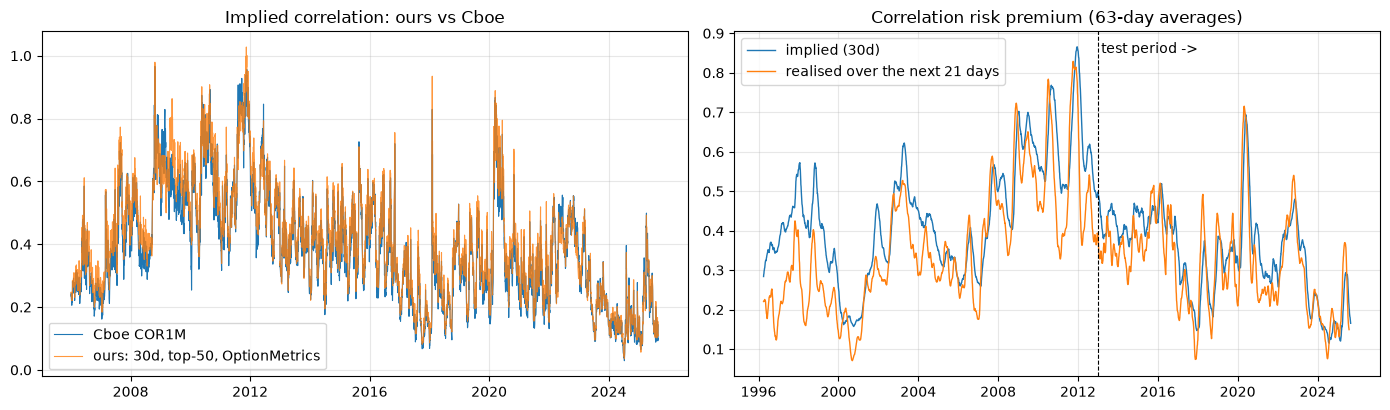

In [24]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
ax[0].plot(val.index, val["COR1M"], lw=0.8, label="Cboe COR1M")
ax[0].plot(val.index, val["ours_30"], lw=0.8, alpha=0.8, label="ours: 30d, top-50, OptionMetrics")
ax[0].set_title("Implied correlation: ours vs Cboe"); ax[0].legend(); ax[0].grid(alpha=0.3)
sm = COR[["rho_imp_30", "rho_real_fwd"]].rolling(63).mean()
ax[1].plot(sm.index, sm["rho_imp_30"], lw=1, label="implied (30d)")
ax[1].plot(sm.index, sm["rho_real_fwd"], lw=1, label="realised over the next 21 days")
ax[1].axvline(pd.Timestamp(STUDY_DESIGN_END), color="k", ls="--", lw=0.8); ax[1].text(pd.Timestamp("2013-03-01"), 0.85, "test period ->")
ax[1].set_title("Correlation risk premium (63-day averages)"); ax[1].legend(); ax[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()


## 4. Event-Variance Decomposition

Scheduled events add a lump of variance to every option expiring after them. Over the option's life the total implied variance is

$$\sigma_T^2\,T = v_d\,T + \sum_{k\in\text{events in }(t,t+T]} J_k^2 .$$

* **Single stocks (earnings):** on the day before the reaction day, both the 30- and 60-day options contain the announcement. So $v_d=(V_{60}-V_{30})/30$ and $J^2=V_{30}-30\,v_d$ (Bennett §6.4; Dubinsky–Johannes).
* **SPX (macro co-jumps):** a term-structure regression failed (logged in the research log), so the index uses the *vol crush*. On an event day the event leaves the 30-day window, and $V_{30}$ drops by its share $\varphi_k$ relative to ordinary days. The same regression, pooled over stocks, measures how much of each stock's variance the macro releases carry, so they are removed from **both** legs.
* **Point in time:** each day uses only estimates available then. The index $\varphi$ comes from an expanding window. Each stock's $J^2$ is the mean of its previous four announcements.

The ex-event implied correlation recomputes $\rho$ from vols with the event variance inside each window removed.

### 4.1 Events inside each option's life
For every day, the number of events inside (t, t+T] takes two binary searches into the sorted event dates: O(N log E) rather than a scan of all events per day.

In [25]:
# ---------------------------------------------------------------- 4.1 Which events fall inside each option's life?
def ols_nw(y, X, lags):
    '''OLS with Newey-West (Bartlett) standard errors - overlapping 30-day windows make residuals autocorrelated.'''
    X = np.column_stack([np.ones(len(y)), X]); b = np.linalg.lstsq(X, y, rcond=None)[0]; u = y - X @ b
    Xu = X * u[:, None]; S = Xu.T @ Xu
    for L in range(1, lags + 1):
        G = Xu[L:].T @ Xu[:-L]; S += (1 - L / (lags + 1)) * (G + G.T)
    XXi = np.linalg.inv(X.T @ X); se = np.sqrt(np.diag(XXi @ S @ XXi))
    return b, se

def count_in_window(ev_days, T):
    '''#events with trading day in (t, t + T calendar days] for every t - two binary searches per day: O(N log E).'''
    ev = np.sort(pd.DatetimeIndex(ev_days).dropna().unique().to_numpy())
    t = tdays_w.to_numpy()
    return np.searchsorted(ev, t + np.timedelta64(T, "D"), side="right") - np.searchsorted(ev, t, side="right")

MACRO = ("FOMC", "CPI", "NFP")                                            # scheduled, dates known ex ante
NM = {T: pd.DataFrame({k: count_in_window(events.loc[events["event"] == k, "tday"], T) for k in MACRO}, index=tdays_w) for T in TENORS}

# earnings: per company, count of reaction days inside (t, t+T]
earn_by = {s: g["react"].to_numpy() for s, g in earn.groupby("secid")}
NE = {T: pd.DataFrame({s: count_in_window(d, T) for s, d in earn_by.items()}, index=tdays_w).reindex(columns=W.columns, fill_value=0)
      for T in TENORS}
COR["n_fomc_30"], COR["n_cpi_30"] = NM[30]["FOMC"], NM[30]["CPI"]
COR["earn_w_30"] = (W_iv * (NE[30] > 0)).sum(axis=1)                      # index weight of names reporting inside 30 days
print("Share of days whose 30d window contains a scheduled FOMC:", f"{(NM[30]['FOMC'] > 0).mean():.0%}",
      "| a CPI:", f"{(NM[30]['CPI'] > 0).mean():.0%}")
print("Weight of basket reporting earnings within 30d - median by calendar month:", COR["earn_w_30"].groupby(COR.index.month).median().round(2).to_dict())


Share of days whose 30d window contains a scheduled FOMC: 66% | a CPI: 96%
Weight of basket reporting earnings within 30d - median by calendar month: {1: 0.72, 2: 0.11, 3: 0.09, 4: 0.75, 5: 0.06, 6: 0.12, 7: 0.72, 8: 0.06, 9: 0.19, 10: 0.72, 11: 0.06, 12: 0.06}


### 4.2 Single stocks: implied earnings-jump variance

In [26]:
# ---------------------------------------------------------------- 4.2 Single stocks: implied earnings-jump variance per event (Bennett / Dubinsky-Johannes)
# Total implied variance to maturity T (in years):  V_T = sigma_T^2 T = v_d T + J^2  if the announcement falls before T.
# On the trading day t* before the reaction day both the 30d and 60d options contain the event, so
#     v_d = (V_60 - V_30) / (60 - 30)   and   J^2 = V_30 - 30 v_d     (calendar days / 365)
# Requires no second announcement inside 60 days (true for quarterly reporters).
def V(T, idx=None):
    return IV[T] ** 2 * T / 365.0

V30, V60 = V(30), V(60)
pos = tdays_w.get_indexer(earn["react"])
earn["tstar"] = tdays_w[np.maximum(pos - 1, 0)]
key = pd.MultiIndex.from_arrays([earn["tstar"], earn["secid"]])
v30 = V30.stack().reindex(key).to_numpy(); v60 = V60.stack().reindex(key).to_numpy()
second = NE[60].stack().reindex(key).to_numpy() > 1
vd = (v60 - v30) / 30.0
earn["J2"] = np.where(second, np.nan, np.clip(v30 - 30 * vd, 0, None))
earn["vd"] = vd
earn["imp_move"] = np.sqrt(earn["J2"])                                    # implied event-day standard deviation
rkey = pd.MultiIndex.from_arrays([earn["react"], earn["secid"]])
earn["real_move"] = RET.stack().reindex(rkey).abs().to_numpy()            # realised |return| on the reaction day
# point-in-time version: average of the company's previous four estimates (known before the next window opens)
earn["J2_pit"] = earn.groupby("secid")["J2"].transform(lambda s: s.shift(1).rolling(4, min_periods=1).mean())
ok_e = earn["J2"].notna() & earn["real_move"].notna()
print(f"Earnings events with a jump estimate: {ok_e.sum():,} of {len(earn):,}")
print(f"Implied event move (median): {earn.loc[ok_e, 'imp_move'].median():.2%} | realised |move| (median): {earn.loc[ok_e, 'real_move'].median():.2%}")
print(f"corr(implied move, realised |move|): {earn.loc[ok_e, ['imp_move', 'real_move']].corr().iloc[0, 1]:.2f}")


Earnings events with a jump estimate: 6,916 of 13,832
Implied event move (median): 3.02% | realised |move| (median): 2.76%
corr(implied move, realised |move|): 0.48


### 4.3 SPX and single stocks: variance resolved by macro releases (vol-crush regression)

In [27]:
# ---------------------------------------------------------------- 4.3 SPX: implied variance resolved by each event type ("vol crush" regression)
# An event on day t sits inside the 30-day option at the close of t-1 and has left it by the close of t, so the 30-day
# total implied variance V_30 = sigma_30^2 * 30/365 drops on event days by the event's implied variance J_k^2.
# Relative to ordinary days (constant c absorbs the normal roll/decay):
#     crush_t = (V_30,t-1 - V_30,t) / V_30,t-1 = c + sum_k phi_k D_k,t + phi_E * EW_t + u_t
# D_k = 1 on FOMC / CPI / payroll days; EW_t = index weight of basket names whose earnings reaction day is t (earnings
# "co-jump" in the index). phi = share of the 30-day implied variance an event carries. Point-in-time phi uses an
# expanding window (X'X and X'y are prefix-summed: one O(N) pass for all ~7,500 daily estimates).
in_basket = W.stack().reindex(pd.MultiIndex.from_arrays([earn["tstar"], earn["secid"]])).fillna(0).to_numpy() > 0
earn = earn[in_basket].reset_index(drop=True)                             # only announcements while the name is in the basket
ER = pd.DataFrame(0.0, index=tdays_w, columns=W.columns)
for s_, g in earn.groupby("secid"):
    ER.loc[g["react"], s_] = 1.0
V30I = V30[SPX_SECID]
crush = ((V30I.shift(1) - V30I) / V30I.shift(1)).clip(-0.5, 0.5)          # cap crash-day vol spikes
REG = pd.DataFrame({k: tdays_w.isin(events.loc[events["event"] == k, "tday"]).astype(float) for k in MACRO}, index=tdays_w)
REG["EARN"] = (W_iv.shift(1) * ER).sum(axis=1)
FAC = list(REG.columns)
okr = crush.notna() & ok_day & ok_day.shift(1, fill_value=False)
Xr = np.column_stack([np.ones(len(REG)), REG.to_numpy()]) * okr.to_numpy()[:, None]
yr = np.where(okr, crush.to_numpy(), 0.0)

def phi_fit(mask):
    b, se = ols_nw(yr[mask & okr.to_numpy()], Xr[mask & okr.to_numpy(), 1:], lags=5)
    return pd.DataFrame({"phi": b[1:], "t": b[1:] / se[1:]}, index=FAC)

for nm, msk in (("Design 1996-2012", tdays_w <= STUDY_DESIGN_END), ("Test 2013-2025", tdays_w > STUDY_DESIGN_END)):
    print(f"{nm}: share of 30-day SPX implied variance resolved per event (NW t)")
    print(phi_fit(msk).T.round(3))
cXX = np.cumsum(np.einsum("ni,nj->nij", Xr, Xr), axis=0); cXy = np.cumsum(Xr * yr[:, None], axis=0)
PHI_pit = np.full((len(Xr), len(FAC)), np.nan)
for n in range(504, len(Xr)):                                              # >= 2 years of history before the first estimate
    PHI_pit[n] = np.linalg.solve(cXX[n - 1], cXy[n - 1])[1:]                # data up to t-1 only
PHI_pit = pd.DataFrame(np.clip(PHI_pit, 0, None), index=tdays_w, columns=FAC)
PHI_full = phi_fit(np.ones(len(tdays_w), bool))["phi"].clip(lower=0)

# The same crush regression pooled over single stocks (stock-days while in the basket): macro releases are CO-JUMPS -
# they also carry part of each stock's implied variance, which must be removed from both legs consistently.
V30S = V30.reindex(columns=W.columns)
crush_s = ((V30S.shift(1) - V30S) / V30S.shift(1)).clip(-0.5, 0.5)
ok_s = crush_s.notna() & (W_iv.shift(1) > 0) & okr.to_numpy()[:, None]
ys = crush_s.where(ok_s).to_numpy()                                       # days x names
Dm = REG[list(MACRO)].to_numpy()                                           # days x K (common to all names)
ERs = ER.to_numpy()                                                        # own-earnings reaction dummy
m_ = np.nan_to_num(ok_s.to_numpy().astype(float))
# per-day sums of X'X and X'y over names, with X = [1, D_FOMC, D_CPI, D_NFP, own-earnings]
n_d = m_.sum(1); e_d = (ERs * m_).sum(1); y_d = np.nansum(ys * m_, 1); ye_d = np.nansum(ys * ERs * m_, 1)
K = len(MACRO)
XXs = np.zeros((len(n_d), K + 2, K + 2)); XYs = np.zeros((len(n_d), K + 2))
base = np.column_stack([np.ones(len(n_d)), Dm])                            # regressors that are the same for every name on a day
XXs[:, :K + 1, :K + 1] = np.einsum("ni,nj->nij", base, base) * n_d[:, None, None]
XXs[:, :K + 1, K + 1] = XXs[:, K + 1, :K + 1] = base * e_d[:, None]
XXs[:, K + 1, K + 1] = e_d
XYs[:, :K + 1] = base * y_d[:, None]; XYs[:, K + 1] = ye_d
names_s = list(MACRO) + ["OWN_EARN"]
for nm, msk in (("Design 1996-2012", tdays_w <= STUDY_DESIGN_END), ("Test 2013-2025", tdays_w > STUDY_DESIGN_END)):
    b = np.linalg.solve(XXs[msk].sum(0), XYs[msk].sum(0))[1:]
    print(f"{nm}, single stocks (pooled): " + "  ".join(f"{k} {v:.3f}" for k, v in zip(names_s, b)))
PHIS_full = pd.Series(np.clip(np.linalg.solve(XXs.sum(0), XYs.sum(0))[1:K + 1], 0, None), index=list(MACRO))
cXXs, cXYs = np.cumsum(XXs, 0), np.cumsum(XYs, 0)
PHIS_pit = np.full((len(n_d), K), np.nan)
for n in range(504, len(n_d)):
    PHIS_pit[n] = np.linalg.solve(cXXs[n - 1], cXYs[n - 1])[1:K + 1]
PHIS_pit = pd.DataFrame(np.clip(PHIS_pit, 0, None), index=tdays_w, columns=list(MACRO))

# realised check: SPX squared return on event days vs implied event variance (phi * V_30 of the day before)
for k in MACRO:
    d = events.loc[events["event"] == k, "tday"]; d = d[d.isin(tdays_w[1:])]
    imp = np.sqrt(PHI_full[k] * V30I.shift(1).reindex(d)).median()
    print(f"  {k}: implied event move {imp:.2%} | realised |SPX| on {k} days {RET[SPX_SECID].reindex(d).abs().median():.2%} "
          f"vs other days {RET[SPX_SECID].drop(d, errors='ignore').abs().median():.2%}")


Design 1996-2012: share of 30-day SPX implied variance resolved per event (NW t)
      FOMC    CPI    NFP   EARN
phi  0.061  0.028  0.024  0.057
t    6.264  3.164  2.645  0.974
Test 2013-2025: share of 30-day SPX implied variance resolved per event (NW t)
      FOMC    CPI    NFP   EARN
phi  0.039  0.033  0.059  0.070
t    2.497  2.455  4.690  0.797
Design 1996-2012, single stocks (pooled): FOMC 0.029  CPI 0.013  NFP 0.002  OWN_EARN 0.113
Test 2013-2025, single stocks (pooled): FOMC 0.020  CPI 0.019  NFP 0.029  OWN_EARN 0.231
  FOMC: implied event move 1.08% | realised |SPX| on FOMC days 0.65% vs other days 0.55%
  CPI: implied event move 0.83% | realised |SPX| on CPI days 0.57% vs other days 0.56%
  NFP: implied event move 0.92% | realised |SPX| on NFP days 0.73% vs other days 0.55%


### 4.4 Ex-event implied correlation

In [28]:
# ---------------------------------------------------------------- 4.4 Ex-event implied vols and implied correlation
def ex_event_vol(V30_tot, J2_in_window):
    '''sigma_ex = sqrt(max(V_30 - J^2, floor) * 365/30); the floor keeps the diffusive vol >= 50% of the raw vol.'''
    return np.sqrt(np.maximum(V30_tot - J2_in_window, 0.25 * V30_tot) * 365 / 30)

def earn_J2_in_window(col):
    '''For each day, sum of J^2 of announcements whose reaction day lies in (t, t+30]. col = 'J2' (ex post) or 'J2_pit'.'''
    out = pd.DataFrame(0.0, index=tdays_w, columns=W.columns)
    t = tdays_w.to_numpy()
    for s_, g in earn.dropna(subset=[col]).groupby("secid"):
        r = g["react"].to_numpy(); j = g[col].to_numpy()
        lo = np.searchsorted(r, t, side="right"); hi = np.searchsorted(r, t + np.timedelta64(30, "D"), side="right")
        cj = np.concatenate([[0.0], np.cumsum(j)])
        out[s_] = cj[hi] - cj[lo]                                          # prefix sums: O(1) per day
    return out

expo = pd.concat([NM[30][list(MACRO)], COR["earn_w_30"].rename("EARN")], axis=1)[FAC]   # events inside (t, t+30]
for tag, J2s, phi in (("expost", earn_J2_in_window("J2"), pd.DataFrame([PHI_full.to_numpy()] * len(tdays_w), index=tdays_w, columns=FAC)),
                      ("pit", earn_J2_in_window("J2_pit"), PHI_pit)):
    phis = pd.DataFrame([PHIS_full.to_numpy()] * len(tdays_w), index=tdays_w, columns=list(MACRO)) if tag == "expost" else PHIS_pit
    macro_share_s = (NM[30][list(MACRO)] * phis[list(MACRO)]).sum(axis=1)          # macro share of each stock's 30d variance
    S_ex = ex_event_vol(V30S, J2s + V30S.mul(macro_share_s, axis=0))
    share = (expo * phi).sum(axis=1)                                       # share of SPX 30d variance due to events in window
    sI_ex = ex_event_vol(V30I, share * V30I)
    rho, _, _ = implied_corr(sI_ex, S_ex, W_iv)
    COR[f"rho_ex_{tag}"] = rho.where(ok_day & sI_ex.notna())
    COR[f"sig_I_ex_{tag}"] = sI_ex
print(COR[["rho_imp_30", "rho_ex_expost", "rho_ex_pit"]].describe().round(3).loc[["count", "mean", "std", "min", "max"]])


       rho_imp_30  rho_ex_expost  rho_ex_pit
count    7463.000       7463.000    7463.000
mean        0.395          0.401       0.400
std         0.161          0.156       0.168
min         0.036          0.076       0.064
max         1.028          1.030       1.282


### 4.5 H1: calendar pattern, raw vs ex-event
Regression of implied correlation on what the 30-day window contains (scheduled FOMC, CPI, index weight reporting earnings), with quarter fixed effects. Newey–West standard errors (21 lags) account for overlapping windows. H1 predicts a positive macro and a negative earnings coefficient in raw ρ, both shrinking ex-event.

In [29]:
# ---------------------------------------------------------------- 4.5 H1: calendar pattern in implied correlation - raw vs ex-event
def h1_table(cols, mask):
    q = COR.index.to_period("Q")
    rows = {}
    for c in cols:
        d = COR.loc[mask, [c, "n_fomc_30", "n_cpi_30", "earn_w_30"]].dropna()
        dq = d - d.groupby(q[mask][COR.loc[mask].index.isin(d.index)]).transform("mean")   # quarter fixed effects
        b, se = ols_nw(dq[c].to_numpy(), dq[["n_fomc_30", "n_cpi_30", "earn_w_30"]].to_numpy(), lags=21)
        rows[c] = {f"{n}": f"{b[i + 1]:+.3f} ({b[i + 1] / se[i + 1]:+.1f})" for i, n in enumerate(["FOMC in window", "CPI in window", "earnings weight in window"])}
    return pd.DataFrame(rows).T

for nm, msk in (("Design 1996-2012", COR.index <= STUDY_DESIGN_END), ("Test 2013-2025", COR.index > STUDY_DESIGN_END)):
    print(f"\n{nm}: coefficient (NW t-stat), quarter fixed effects")
    print(h1_table(["rho_imp_30", "rho_ex_expost", "rho_ex_pit"], msk))



Design 1996-2012: coefficient (NW t-stat), quarter fixed effects
              FOMC in window  CPI in window earnings weight in window
rho_imp_30     -0.001 (-0.2)  +0.008 (+1.5)             -0.060 (-6.5)
rho_ex_expost  -0.014 (-3.3)  +0.008 (+1.5)             +0.030 (+3.0)
rho_ex_pit     -0.019 (-3.5)  -0.001 (-0.2)             +0.048 (+3.7)

Test 2013-2025: coefficient (NW t-stat), quarter fixed effects
              FOMC in window  CPI in window earnings weight in window
rho_imp_30     +0.003 (+0.4)  +0.002 (+0.2)             -0.114 (-8.4)
rho_ex_expost  -0.008 (-1.2)  -0.011 (-1.5)             -0.004 (-0.3)
rho_ex_pit     -0.008 (-1.2)  -0.004 (-0.5)             -0.010 (-0.7)


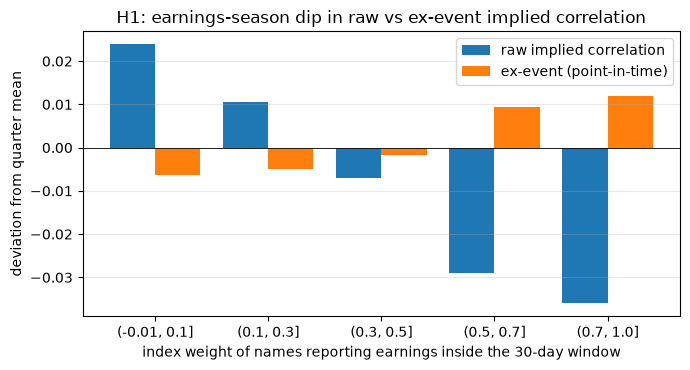

In [30]:
q = COR.index.to_period("Q")
dm = COR[["rho_imp_30", "rho_ex_pit"]] - COR[["rho_imp_30", "rho_ex_pit"]].groupby(q).transform("mean")
bins = pd.cut(COR["earn_w_30"], [-0.01, 0.1, 0.3, 0.5, 0.7, 1.0])
prof = dm.groupby(bins, observed=True).mean()
fig, ax = plt.subplots(figsize=(7, 3.8))
x = np.arange(len(prof))
ax.bar(x - 0.2, prof["rho_imp_30"], 0.4, label="raw implied correlation")
ax.bar(x + 0.2, prof["rho_ex_pit"], 0.4, label="ex-event (point-in-time)")
ax.set_xticks(x); ax.set_xticklabels([str(b) for b in prof.index]); ax.axhline(0, color="k", lw=0.6)
ax.set_xlabel("index weight of names reporting earnings inside the 30-day window"); ax.set_ylabel("deviation from quarter mean")
ax.set_title("H1: earnings-season dip in raw vs ex-event implied correlation"); ax.legend(); ax.grid(alpha=0.3, axis="y")
plt.tight_layout(); plt.show()


### 4.6 H2: where the correlation risk premium sits
(a) Premium in correlation units, raw vs ex-event (event days also removed from the realised side). (b) Premium per event in variance units: implied event variance priced the day before, minus the realised squared move.

In [31]:
# ---------------------------------------------------------------- 4.6 H2: where does the correlation risk premium sit?
# (a) premium in correlation units: implied minus subsequently realised, raw vs ex-event (event days removed from the
#     realised side too: macro days for every name, own reaction days for each stock).
macro_days = events.loc[events["event"].isin(MACRO), "tday"].unique()
R2x = R2.copy()
R2x.loc[R2x.index.isin(macro_days)] = np.nan
R2x[ER.reindex(columns=R2x.columns, fill_value=0).to_numpy() > 0] = np.nan
RVx = rv(R2x, fwd=True)
Wr, _ = renorm(W, RVx.notna())
COR["rho_real_ex_fwd"] = implied_corr(RVx[SPX_SECID], RVx, Wr)[0].where(ok_day)
COR["crp_ex"] = COR["rho_ex_pit"] - COR["rho_real_ex_fwd"]

def mean_nw(x, lags=21):
    x = x.dropna(); b, se = ols_nw(x.to_numpy(), np.empty((len(x), 0)), lags)
    return f"{b[0]:+.3f} (t {b[0] / se[0]:+.1f})"

rows = {}
for nm, msk in (("design 1996-2012", COR.index <= STUDY_DESIGN_END), ("test 2013-2025", COR.index > STUDY_DESIGN_END)):
    rows[nm] = {"raw: implied - realised": mean_nw(COR.loc[msk, "crp"]), "ex-event: implied - realised": mean_nw(COR.loc[msk, "crp_ex"])}
print(pd.DataFrame(rows))

# (b) premium per event in variance units: implied event variance (priced the day before) minus realised squared move
spx_ev = []
for k in MACRO:
    d = pd.DatetimeIndex(events.loc[events["event"] == k, "tday"]); d = d[d.isin(tdays_w[1:]) & (d >= tdays_w[504])]
    prev = tdays_w[tdays_w.get_indexer(d) - 1]
    J2 = PHI_pit[k].reindex(d).to_numpy() * V30I.reindex(prev).to_numpy()
    spx_ev.append(pd.DataFrame({"type": k, "date": d, "J2": J2, "r2": RET[SPX_SECID].reindex(d).to_numpy() ** 2}))
spx_ev = pd.concat(spx_ev).dropna()
stk_ev = earn.dropna(subset=["J2", "real_move"]).assign(type="EARNINGS", date=lambda d: d["react"], r2=lambda d: d["real_move"] ** 2)[["type", "date", "J2", "r2"]]
ev_all = pd.concat([spx_ev, stk_ev], ignore_index=True)
ev_all["period"] = np.where(ev_all["date"] <= STUDY_DESIGN_END, "design", "test")
ev_all["unrealised_share"] = 1 - ev_all["r2"] / ev_all["J2"].where(ev_all["J2"] > 0)     # share of priced event variance NOT realised
tab = ev_all.groupby(["type", "period"]).agg(n=("J2", "size"), implied_move=("J2", lambda x: np.sqrt(x).median()),
                                             realised_move=("r2", lambda x: np.sqrt(x).median()),
                                             mean_J2_minus_r2_bp=("J2", lambda x: 1e4 * (x - ev_all.loc[x.index, "r2"]).mean()),
                                             t=("J2", lambda x: (x - ev_all.loc[x.index, "r2"]).mean() / ((x - ev_all.loc[x.index, "r2"]).std() / np.sqrt(len(x)))))
print(tab.round(4))


                              design 1996-2012   test 2013-2025
raw: implied - realised       +0.079 (t +10.2)  +0.025 (t +2.9)
ex-event: implied - realised   +0.062 (t +6.7)  +0.007 (t +0.8)
                    n  implied_move  realised_move  mean_J2_minus_r2_bp       t
type     period                                                                
CPI      design   180        0.0104         0.0063              -0.5277 -1.7489
         test     152        0.0062         0.0053              -0.7389 -2.6281
EARNINGS design  3374        0.0275         0.0259               2.4564  2.3668
         test    2510        0.0312         0.0277              -4.4000 -4.1320
FOMC     design   120        0.0138         0.0066               0.6271  2.0924
         test     100        0.0089         0.0061              -0.0748 -0.4690
NFP      design   184        0.0107         0.0075              -0.2229 -1.3171
         test     156        0.0074         0.0060              -0.4567 -1.8486


## 5. Strategy: theta-weighted, delta-hedged straddle dispersion

On each monthly entry date (first trading day after the third Friday):

* **Short** ATM SPX straddles worth \$1 of index notional ($N_I = 1/S_I$).
* **Long** ATM straddles on each basket name, $N_i = k\,w_i/S_i$, where $k$ makes the long leg's theta equal the short leg's theta (Bennett's theta-weighting). The book is then time-decay neutral, and its P&L is approximately $\sum_i w_i\sigma_i^2(\rho_{imp}-\rho_{real})$: a trade on implied vs realised correlation.
* Options are held to the next standard monthly expiry (20–45 days). Each straddle is delta-hedged at every close with Black–Scholes deltas at its entry IV. Hedge gains use total returns, so a short stock pays the dividend. The hedge is unwound at the settlement print.
* **Costs:** a fraction *c* of the quoted half-spread on every option (c = 0 mid, 0.5, 1 = bid/ask), plus 1 bp (stocks) / 0.5 bp (index) on hedge turnover. Premiums are financed at the 3-month T-bill rate.

Pre-registered variants (research log): **V1** vanilla every month. **V2** event-timed: long straddles only on names reporting earnings inside the holding period. **V3** signal-filtered: V1 only when the point-in-time ex-event implied correlation is above its trailing one-year median.

### 5.1 Pricing every straddle (entry quotes, payoff, hedge P&L)

In [32]:
# ---------------------------------------------------------------- 5.1 ATM straddles on each monthly entry date, held to the next monthly expiry
from math import erf, sqrt, log
_ncdf = np.frompyfunc(lambda x: 0.5 * (1.0 + erf(x / sqrt(2.0))), 1, 1)
DTE_LO, DTE_HI = 20, 45                                                    # calendar days to the next standard monthly expiry
rf_d = rf.reindex(tdays_w).ffill().bfill()

def pick_straddles(e):
    '''All securities on entry date e: nearest standard monthly expiry in [20, 45] days, strike closest to spot with both
    a call and a put quoted. One row per security.'''
    c = ch[(ch["date"] == e) & ch["standard"] & ch["dte"].between(DTE_LO, DTE_HI)]
    if c.empty:
        return None
    c = c[c["exdate"] == c.groupby("secid")["exdate"].transform("min")]
    spot = CLOSE.loc[e]
    c = c.assign(S=c["secid"].map(spot))
    pv = c.pivot_table(index=["secid", "exdate", "strike"], columns="cp",
                       values=["best_bid", "best_offer", "mid", "impl_volatility", "theta", "vega", "am_settlement", "S"], aggfunc="first")
    pv = pv.dropna(subset=[("mid", "C"), ("mid", "P")])
    if pv.empty:
        return None
    df = pd.DataFrame({"bid": pv[("best_bid", "C")] + pv[("best_bid", "P")], "ask": pv[("best_offer", "C")] + pv[("best_offer", "P")],
                       "mid": pv[("mid", "C")] + pv[("mid", "P")], "iv": (pv[("impl_volatility", "C")] + pv[("impl_volatility", "P")]) / 2,
                       "theta": pv[("theta", "C")] + pv[("theta", "P")], "vega": pv[("vega", "C")] + pv[("vega", "P")],
                       "am": pv[("am_settlement", "C")].fillna(0), "S": pv[("S", "C")]}).reset_index()
    df = df[df["S"] > 0]
    df = df.loc[(df["strike"] - df["S"]).abs().groupby(df["secid"]).idxmin()]
    df["date"] = e
    return df

def straddle_path(r):
    '''Long-straddle P&L per unit held to expiry with a daily Black-Scholes delta hedge at the entry IV.
    Hedge gain uses TOTAL returns (a short stock position pays the dividend); the underlying is kept in entry-date
    units with OptionMetrics' cumulative adjustment factor, so splits during the holding period are handled.'''
    s = int(r.secid); e = r.date
    d_set, S_set = settle_price(s, r.exdate, bool(r.am))
    i0, i1 = tdays_w.get_loc(e), tdays_w.get_loc(d_set)
    days = tdays_w[i0:i1 + 1]
    S = (CLOSE[s].iloc[i0:i1 + 1] * CFADJ[s].iloc[i0:i1 + 1].ffill() / CFADJ[s].iloc[i0]).to_numpy()
    ST = S_set * CFADJ[s].iloc[i1] / CFADJ[s].iloc[i0]
    rt = RET[s].iloc[i0 + 1:i1 + 1].to_numpy().copy()
    if not np.isfinite(S[0]):
        return np.nan, np.nan, np.nan
    if not (np.isfinite(S).all() and np.isfinite(rt).all() and np.isfinite(ST)):
        # price gap, or the stock stopped trading before expiry (merger / delisting): carry the last price forward and
        # settle at the last available price instead of silently dropping the position (survivorship)
        GAPS.append((e, s))
        S = pd.Series(S).ffill().to_numpy()
        rt = np.where(np.isfinite(rt), rt, S[1:] / S[:-1] - 1)
        ST = ST if np.isfinite(ST) else S[-1]
    if len(rt):
        rt[-1] = ST / S[-2] - 1                                            # hedge is unwound at the settlement print (AM: Friday open)
    tau = np.maximum((r.exdate - days[:-1]).days.to_numpy() / 365.0, 1 / 365)
    rr = rf_d.iloc[i0:i1].to_numpy()
    d1 = (np.log(S[:-1] / r.strike) + (rr + 0.5 * r.iv ** 2) * tau) / (r.iv * np.sqrt(tau))
    delta = 2 * _ncdf(d1).astype(float) - 1                                # straddle delta
    hedge = -np.sum(delta * S[:-1] * rt)                                   # short delta shares, rebalanced at each close
    turnover = np.abs(np.diff(np.concatenate([[0.0], delta, [0.0]]))) @ np.concatenate([S[:-1], [ST]])
    payoff = abs(ST - r.strike)
    return payoff, hedge, turnover

legs, GAPS = [], []
t0 = time.time()
for e in entry_w:
    df = pick_straddles(e)
    if df is None:
        continue
    df = df[df["secid"].isin(set(W.columns[W.loc[e] > 0]) | {SPX_SECID})]
    out = np.array([straddle_path(r) for r in df.itertuples()], dtype=float)
    df["payoff"], df["hedge"], df["turnover"] = out[:, 0], out[:, 1], out[:, 2]
    legs.append(df)
legs = pd.concat(legs, ignore_index=True).dropna(subset=["payoff", "hedge"])
legs["tau"] = (legs["exdate"] - legs["date"]).dt.days / 365.0
legs["rf"] = rf_d.reindex(legs["date"]).to_numpy()
legs["is_index"] = legs["secid"] == SPX_SECID
print(f"Straddles priced: {len(legs):,} on {legs['date'].nunique()} entry dates ({time.time() - t0:.0f}s) | "
      f"index legs: {legs['is_index'].sum()} | median names per month: {legs[~legs['is_index']].groupby('date').size().median():.0f}")
print(f"Legs with a price gap or early delisting (settled at last available price, not dropped): {len(GAPS)} of {len(legs):,}")
print("Median quoted half-spread / mid:", f"index {((legs['ask'] - legs['bid']) / 2 / legs['mid'])[legs['is_index']].median():.1%}",
      f"stocks {((legs['ask'] - legs['bid']) / 2 / legs['mid'])[~legs['is_index']].median():.1%}")


Straddles priced: 17,925 on 356 entry dates (20s) | index legs: 356 | median names per month: 50
Legs with a price gap or early delisting (settled at last available price, not dropped): 16 of 17,925
Median quoted half-spread / mid: index 2.7% stocks 2.1%


### 5.2 Building the dispersion book and its monthly P&L

In [33]:
# ---------------------------------------------------------------- 5.2 Theta-weighted dispersion book (Bennett section 6.3)
# Short N_I = 1/S_I SPX straddles ($1 of index notional); long N_i = k w_i / S_i straddles on each name, with k chosen
# so the long leg's theta equals the short leg's theta (time decay neutral). P&L ~ sum_i w_i s_i^2 (rho_imp - rho_real).
EARN_IN = {}
for e in legs["date"].unique():
    X = legs.loc[(legs["date"] == e) & ~legs["is_index"], ["secid", "exdate"]]
    EARN_IN[e] = {int(s) for s, x in zip(X["secid"], X["exdate"])
                  if s in earn_by and ((earn_by[s] > np.datetime64(e)) & (earn_by[s] <= np.datetime64(x))).any()}
sig = COR["rho_ex_pit"]
SIG_ON = (sig > sig.rolling(252, min_periods=126).median().shift(1))       # V3 filter, decided at the entry close

def book(e, variant):
    L = legs[legs["date"] == e]
    I = L[L["is_index"]]
    if I.empty:
        return None
    St = L[~L["is_index"]].copy()
    if variant == "V2_event_timed":
        St = St[St["secid"].isin(EARN_IN.get(e, set()))]
    if variant == "V3_signal" and not bool(SIG_ON.get(e, False)):
        return None
    if St.empty:
        return None
    w = W.loc[e].reindex(St["secid"]).to_numpy()
    w = w / w.sum()
    I = I.iloc[0]
    n_I = 1.0 / I["S"]
    n_i = w / St["S"].to_numpy()
    k = (n_I * I["theta"]) / np.sum(n_i * St["theta"].to_numpy())          # theta-neutral scaling
    St = St.assign(n=k * n_i)
    return I, n_I, St

def pnl(e, variant, c=0.0, hedge_bp_stock=1.0, hedge_bp_index=0.5):
    '''Dispersion P&L per $1 of index notional. c = fraction of the quoted half-spread paid on each leg
    (0 = mid, 1 = buy at ask / sell at bid).'''
    b = book(e, variant)
    if b is None:
        return None
    I, n_I, St = b
    half_I, half_S = (I["ask"] - I["bid"]) / 2, (St["ask"] - St["bid"]).to_numpy() / 2
    prem_I = I["mid"] - c * half_I                                         # we SELL the index straddle
    prem_S = St["mid"].to_numpy() + c * half_S                             # and BUY single-stock straddles
    fin = lambda p, r: p * (np.exp(r * I["tau"]) - 1)                      # premium financed / invested at the T-bill rate
    long_S = np.sum(St["n"].to_numpy() * (St["payoff"].to_numpy() + St["hedge"].to_numpy() - prem_S - fin(prem_S, St["rf"].to_numpy())
                                          - hedge_bp_stock * 1e-4 * St["turnover"].to_numpy()))
    short_I = n_I * (prem_I + fin(prem_I, I["rf"]) - I["payoff"] - I["hedge"] - hedge_bp_index * 1e-4 * I["turnover"])
    return {"date": e, "pnl": long_S + short_I, "stock_leg": long_S, "index_leg": short_I, "n_names": len(St),
            "vega_ratio": np.sum(St["n"].to_numpy() * St["vega"].to_numpy()) / (n_I * I["vega"]),
            "index_prem": n_I * I["mid"]}

VARIANTS = ["V1_vanilla", "V2_event_timed", "V3_signal"]
COSTS = {"mid": 0.0, "half": 0.5, "full": 1.0}
res = {}
for v in VARIANTS:
    for cn, c in COSTS.items():
        rows = [x for x in (pnl(e, v, c) for e in sorted(legs["date"].unique())) if x is not None]
        res[(v, cn)] = pd.DataFrame(rows).set_index("date")
print({f"{v}/{cn}": len(d) for (v, cn), d in res.items() if cn == "mid"})


{'V1_vanilla/mid': 356, 'V2_event_timed/mid': 343, 'V3_signal/mid': 166}


## 6. Backtest & Out-of-Sample Evaluation

P&L is per \$1 of SPX notional per monthly holding period (non-overlapping), in basis points. The design period 1996–2012 was used to build everything. The test period 2013-01 to 2025-08 is reported once, with no changes (research log). The Deflated Sharpe Ratio (Bailey & López de Prado, 2014) adjusts for the three variants tried and for non-normal returns. The break-even cost is the fraction of the quoted half-spread at which the mean P&L reaches zero.

### 6.1 Design period 1996–2012

In [34]:
# ---------------------------------------------------------------- 6.1 Performance: design vs test, three cost levels
from statistics import NormalDist
N01 = NormalDist()

def stats(x):
    '''x: monthly P&L per $1 of index notional (non-overlapping holding periods).'''
    x = x.dropna()
    if len(x) < 6:
        return {}
    cum = x.cumsum(); dd = (cum - cum.cummax()).min()
    sr = x.mean() / x.std()
    return {"months": len(x), "cum_bp": 1e4 * x.sum(), "mean_bp": 1e4 * x.mean(), "vol_bp": 1e4 * x.std(), "sharpe_ann": sr * np.sqrt(12),
            "t_stat": sr * np.sqrt(len(x)), "hit": (x > 0).mean(), "worst_bp": 1e4 * x.min(), "maxDD_bp": 1e4 * dd,
            "skew": x.skew(), "CVaR5_bp": 1e4 * x[x <= x.quantile(0.05)].mean()}

PER = {"design": lambda d: d[d.index <= STUDY_DESIGN_END], "test": lambda d: d[d.index > STUDY_DESIGN_END]}
perf = pd.DataFrame({(v, cn, p): stats(f(res[(v, cn)]["pnl"])) for (v, cn) in res for p, f in PER.items()}).T
perf.index.names = ["variant", "cost", "period"]
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
print(perf.xs("design", level="period").round(2).to_string())


                     months   cum_bp  mean_bp  vol_bp  sharpe_ann  t_stat  hit  worst_bp  maxDD_bp  skew  CVaR5_bp
variant        cost                                                                                               
V1_vanilla     mid   204.00 8,154.72    39.97   77.41        1.79    7.38 0.68   -182.90   -259.15  0.66    -96.61
               half  204.00 5,269.68    25.83   76.29        1.17    4.84 0.58   -193.86   -351.93  0.61   -111.98
               full  204.00 2,384.64    11.69   75.58        0.54    2.21 0.50   -204.83   -868.37  0.54   -128.04
V2_event_timed mid   192.00 8,914.08    46.43  102.80        1.56    6.26 0.67   -250.47   -394.47  0.37   -157.60
               half  192.00 6,205.45    32.32  101.93        1.10    4.39 0.60   -265.54   -456.79  0.34   -173.32
               full  192.00 3,496.82    18.21  101.43        0.62    2.49 0.56   -283.01   -547.31  0.31   -189.50
V3_signal      mid    98.00 4,716.28    48.13   85.32        1.95    5.58 0.68  

### 6.2 Test period 2013–2025 (evaluated once)

In [35]:
print(perf.xs("test", level="period").round(2).to_string())


                     months   cum_bp  mean_bp  vol_bp  sharpe_ann  t_stat  hit  worst_bp  maxDD_bp  skew  CVaR5_bp
variant        cost                                                                                               
V1_vanilla     mid   152.00   998.55     6.57   61.73        0.37    1.31 0.53   -157.65   -393.21  0.58   -113.32
               half  152.00   269.46     1.77   62.34        0.10    0.35 0.48   -177.66   -484.32  0.46   -122.77
               full  152.00  -459.64    -3.02   63.31       -0.17   -0.59 0.46   -227.74   -640.56  0.27   -132.22
V2_event_timed mid   151.00 1,940.00    12.85   97.02        0.46    1.63 0.54   -225.24   -684.47  1.55   -151.43
               half  151.00 1,197.10     7.93   97.60        0.28    1.00 0.52   -256.27   -918.53  1.46   -161.83
               full  151.00   454.21     3.01   98.33        0.11    0.38 0.48   -287.30 -1,152.59  1.36   -175.41
V3_signal      mid    68.00   841.61    12.38   72.90        0.59    1.40 0.51  

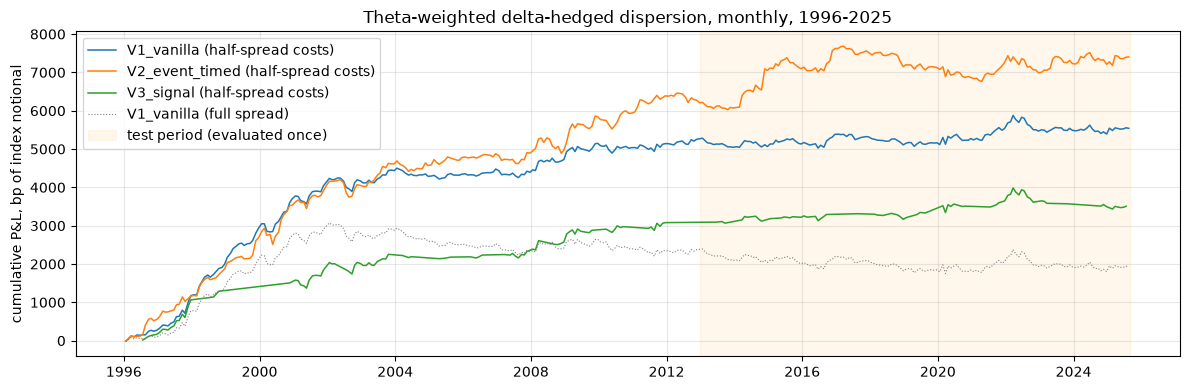

In [36]:
fig, ax = plt.subplots(figsize=(12, 4))
for v in VARIANTS:
    ax.plot(res[(v, "half")]["pnl"].cumsum() * 1e4, lw=1.1, label=f"{v} (half-spread costs)")
ax.plot(res[("V1_vanilla", "full")]["pnl"].cumsum() * 1e4, lw=0.8, ls=":", color="grey", label="V1_vanilla (full spread)")
ax.axvspan(pd.Timestamp(STUDY_DESIGN_END), COR.index[-1], color="orange", alpha=0.08, label="test period (evaluated once)")
ax.set_ylabel("cumulative P&L, bp of index notional"); ax.set_title("Theta-weighted delta-hedged dispersion, monthly, 1996-2025")
ax.legend(loc="upper left"); ax.grid(alpha=0.3); plt.tight_layout(); plt.show()


### 6.3 Break-even transaction cost and Deflated Sharpe Ratio

In [37]:
# ---------------------------------------------------------------- 6.3 Break-even cost and Deflated Sharpe Ratio
def breakeven_c(v, period):
    '''Fraction of the quoted half-spread at which the mean P&L is zero (P&L is linear in c).'''
    m0 = PER[period](res[(v, "mid")]["pnl"]).mean(); m1 = PER[period](res[(v, "full")]["pnl"]).mean()
    return m0 / (m0 - m1) if m0 > 0 else 0.0

def deflated_sharpe(x, sr_trials):
    '''Bailey & Lopez de Prado (2014): probability the true SR > 0 after N trials, with non-normal returns.'''
    x = x.dropna(); n = len(x); sr = x.mean() / x.std(); g3 = x.skew(); g4 = x.kurt() + 3
    N = len(sr_trials); v = np.var(sr_trials, ddof=1)
    sr0 = np.sqrt(v) * ((1 - 0.5772) * N01.inv_cdf(1 - 1 / N) + 0.5772 * N01.inv_cdf(1 - 1 / (N * np.e)))
    return N01.cdf((sr - sr0) * np.sqrt(n - 1) / np.sqrt(1 - g3 * sr + (g4 - 1) / 4 * sr ** 2)), sr0

rows = {}
for p in PER:
    trials = [PER[p](res[(v, "half")]["pnl"]).pipe(lambda x: x.mean() / x.std()) for v in VARIANTS]
    for v in VARIANTS:
        dsr, sr0 = deflated_sharpe(PER[p](res[(v, "half")]["pnl"]), trials)
        rows[(v, p)] = {"break-even share of half-spread": breakeven_c(v, p), "DSR (half-spread costs)": dsr, "SR hurdle (monthly)": sr0}
print(pd.DataFrame(rows).T.round(3).to_string())


                       break-even share of half-spread  DSR (half-spread costs)  SR hurdle (monthly)
V1_vanilla     design                             1.41                     1.00                 0.02
V2_event_timed design                             1.65                     1.00                 0.02
V3_signal      design                             1.44                     1.00                 0.02
V1_vanilla     test                               0.69                     0.51                 0.03
V2_event_timed test                               1.31                     0.76                 0.03
V3_signal      test                               1.02                     0.69                 0.03


### 6.4 Attribution: does the book earn the correlation premium?

In [38]:
# ---------------------------------------------------------------- 6.4 Does the book earn the correlation premium? P&L vs (implied - realised) correlation at entry
v1 = res[("V1_vanilla", "mid")].join(COR[["rho_imp_30", "rho_real_fwd", "crp", "rho_ex_pit"]], how="left").dropna(subset=["pnl", "crp"])
b, se = ols_nw(v1["pnl"].to_numpy(), v1[["crp"]].to_numpy(), lags=1)
print(f"V1 monthly P&L on the realised correlation premium at entry: slope {b[1]:.4f} (t {b[1] / se[1]:.1f}), R2 "
      f"{np.corrcoef(v1['pnl'], v1['crp'])[0, 1] ** 2:.2f}")
print("Leg contribution (mean bp per month, mid):", (1e4 * res[("V1_vanilla", "mid")][["stock_leg", "index_leg"]].groupby(
      np.where(res[("V1_vanilla", "mid")].index <= STUDY_DESIGN_END, "design", "test")).mean()).round(1).to_dict())


V1 monthly P&L on the realised correlation premium at entry: slope 0.0280 (t 8.6), R2 0.25
Leg contribution (mean bp per month, mid): {'stock_leg': {'design': -4.1, 'test': 4.7}, 'index_leg': {'design': 44.1, 'test': 1.9}}


## 7. Diagnostics: Efficiency & Risk Touchpoints

**Efficiency.** Three algorithmic choices are measured against naive versions:
* the O(n) identity for the pairwise sum;
* prefix sums for the rolling and expanding event-variance regressions;
* binary search for "events inside each window".

Elsewhere in the pipeline: a hash map for the dated permno→secid link (`wrds_extract.py`), weekly IN-list queries against indexed tables, a resumable cache with SHA-256 manifest, and binary search for the basket in force.

**Risk.** Dispersion is short correlation and short volga, so the danger is a correlation spike. Below: exposure regressions, net vega of the theta-neutral book, P&L through named stress episodes, the worst months and the drawdown path.

### 7.1 Efficiency

In [39]:
# ---------------------------------------------------------------- 7.1 Efficiency touchpoint: what the algorithmic choices buy
def timeit(f, reps=3):
    best = 1e9
    for _ in range(reps):
        t = time.perf_counter(); f(); best = min(best, time.perf_counter() - t)
    return best

rng = np.random.default_rng(1)
rows = []
for n in (50, 200, 500, 1000):                                             # basket size (Cboe COR uses 50; full S&P 500 = 500)
    w = rng.dirichlet(np.ones(n)); s = rng.uniform(0.15, 0.6, n); sI = 0.2
    t_loop = timeit(lambda: implied_corr_pairwise(sI, s, w), reps=1)
    t_outer = timeit(lambda: (sI ** 2 - np.sum(w ** 2 * s ** 2)) / (np.sum(np.outer(w * s, w * s)) - np.sum(w ** 2 * s ** 2)))
    t_lin = timeit(lambda: (sI ** 2 - np.sum(w ** 2 * s ** 2)) / (np.sum(w * s) ** 2 - np.sum(w ** 2 * s ** 2)))
    rows.append({"n names": n, "python double loop O(n^2) [ms]": 1e3 * t_loop, "numpy outer product O(n^2) [ms]": 1e3 * t_outer,
                 "identity O(n) [ms]": 1e3 * t_lin, "loop / O(n)": t_loop / t_lin})
eff = pd.DataFrame(rows).set_index("n names")
eff["full sample, loop [s]"] = eff["python double loop O(n^2) [ms]"] * len(tdays_w) / 1e3
t_vec = timeit(lambda: implied_corr(IV[30][SPX_SECID], IV[30], W_iv))
print(eff.round(4).to_string())
print(f"Whole 1996-2025 panel (7,465 days x 50 names), vectorised O(n) identity: {t_vec * 1e3:.0f} ms")

# rolling regression: prefix sums vs re-estimating on a 252-day window every day
def naive_roll():
    out = []
    for n in range(504, len(Xr)):
        Xw, yw = Xr[n - 252:n], yr[n - 252:n]
        out.append(np.linalg.lstsq(Xw, yw, rcond=None)[0])
    return out
def prefix_roll():
    cX = np.cumsum(np.einsum("ni,nj->nij", Xr, Xr), 0); cy = np.cumsum(Xr * yr[:, None], 0)
    return [np.linalg.solve(cX[n - 1] - cX[n - 253], cy[n - 1] - cy[n - 253]) for n in range(504, len(Xr))]
t_naive, t_prefix = timeit(naive_roll, 1), timeit(prefix_roll, 1)
ev_np = np.sort(events.loc[events["event"] == "FOMC", "tday"].to_numpy())
t_bs = timeit(lambda: count_in_window(ev_np, 30))
t_lin_scan = timeit(lambda: [int(((ev_np > np.datetime64(t)) & (ev_np <= np.datetime64(t) + np.timedelta64(30, "D"))).sum()) for t in tdays_w], 1)
print(pd.DataFrame({"naive": [t_naive, t_lin_scan], "chosen": [t_prefix, t_bs]},
                   index=["rolling event-variance regression (O(N*w) -> O(N) prefix sums)", "events inside each window (scan O(N*E) -> binary search O(N log E))"])
      .assign(speedup=lambda d: d["naive"] / d["chosen"]).round(4).to_string())


         python double loop O(n^2) [ms]  numpy outer product O(n^2) [ms]  identity O(n) [ms]  loop / O(n)  full sample, loop [s]
n names                                                                                                                         
50                                 1.17                             0.02                0.01       166.80                   8.72
200                               13.93                             0.04                0.01     1,990.69                 104.02
500                               68.04                             0.63                0.01     9,195.02                 507.94
1000                             302.69                             3.32                0.01    23,284.00               2,259.59
Whole 1996-2025 panel (7,465 days x 50 names), vectorised O(n) identity: 75 ms
                                                                     naive  chosen  speedup
rolling event-variance regression (O(N*w) -> O(N) prefi

### 7.2 Risk

In [40]:
# ---------------------------------------------------------------- 7.2 Risk touchpoint: tails, stress episodes, exposures
m = res[("V1_vanilla", "half")]
spx_m = pd.Series({e: np.prod(1 + RET[SPX_SECID].loc[e:x].iloc[1:]) - 1 for e, x in
                   legs[legs["is_index"]].set_index("date")["exdate"].items()})
vix = read_cboe("VIX")
dvix = pd.Series({e: vix.asof(x) - vix.asof(e) for e, x in legs[legs["is_index"]].set_index("date")["exdate"].items()})
drho = pd.Series({e: COR["rho_imp_30"].asof(x) - COR["rho_imp_30"].asof(e) for e, x in legs[legs["is_index"]].set_index("date")["exdate"].items()})
expo = pd.DataFrame({"pnl": m["pnl"], "spx": spx_m, "dvix": dvix, "drho": drho}).dropna()
for f in ("spx", "dvix", "drho"):
    b, se = ols_nw(expo["pnl"].to_numpy(), expo[[f]].to_numpy(), lags=1)
    print(f"V1 monthly P&L on {f:>4}: beta {b[1]:+.4f} (t {b[1] / se[1]:+.1f}) | corr {expo['pnl'].corr(expo[f]):+.2f}")
print("Net vega of the theta-neutral book (long-leg vega / short-leg vega): median", f"{m['vega_ratio'].median():.2f}",
      "| 5-95%:", m["vega_ratio"].quantile([0.05, 0.95]).round(2).tolist())
STRESS = {"LTCM / Russia (Aug-Sep 1998)": ("1998-07-20", "1998-10-20"), "Dot-com peak (Mar-Apr 2000)": ("2000-03-01", "2000-05-01"),
          "9/11 (Sep 2001)": ("2001-08-20", "2001-10-20"), "Lehman (Sep-Nov 2008)": ("2008-09-01", "2008-11-30"),
          "Flash crash (May 2010)": ("2010-04-19", "2010-06-21"), "US downgrade (Aug 2011)": ("2011-07-18", "2011-09-19"),
          "Volmageddon (Feb 2018)": ("2018-01-22", "2018-03-19"), "COVID (Feb-Mar 2020)": ("2020-02-18", "2020-04-20"),
          "2022 rate shock": ("2022-01-18", "2022-06-21")}
print(pd.DataFrame({k: {v: 1e4 * res[(v, "half")]["pnl"].loc[a:b].sum() for v in VARIANTS} for k, (a, b) in STRESS.items()}).T.round(0).to_string())
print("Five worst months, V1 (bp of index notional, half-spread costs):")
print((1e4 * m["pnl"].nsmallest(5)).round(0).to_string())


V1 monthly P&L on  spx: beta -0.0065 (t -0.6) | corr -0.05
V1 monthly P&L on dvix: beta -0.0074 (t -0.7) | corr -0.06
V1 monthly P&L on drho: beta -0.0153 (t -4.7) | corr -0.24
Net vega of the theta-neutral book (long-leg vega / short-leg vega): median 0.65 | 5-95%: [0.47, 0.86]
                              V1_vanilla  V2_event_timed  V3_signal
LTCM / Russia (Aug-Sep 1998)      170.00           74.00     225.00
Dot-com peak (Mar-Apr 2000)      -211.00         -159.00       0.00
9/11 (Sep 2001)                    12.00          -32.00      12.00
Lehman (Sep-Nov 2008)             -71.00         -197.00     -71.00
Flash crash (May 2010)           -131.00         -141.00     -12.00
US downgrade (Aug 2011)           133.00          220.00     133.00
Volmageddon (Feb 2018)            -82.00           -1.00     -35.00
COVID (Feb-Mar 2020)              216.00          -12.00     216.00
2022 rate shock                   292.00           97.00     292.00
Five worst months, V1 (bp of index notio

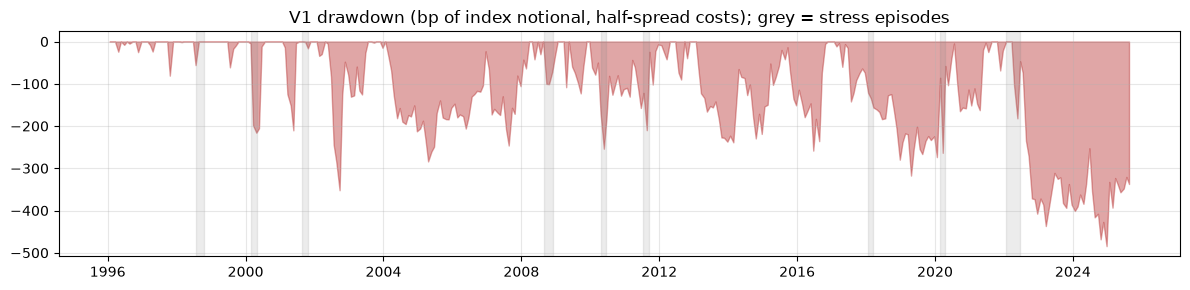

In [41]:
cum = m["pnl"].cumsum() * 1e4
fig, ax = plt.subplots(figsize=(12, 3))
ax.fill_between(cum.index, cum - cum.cummax(), 0, color="firebrick", alpha=0.4)
for k, (a, b) in STRESS.items():
    ax.axvspan(pd.Timestamp(a), pd.Timestamp(b), color="grey", alpha=0.15)
ax.set_title("V1 drawdown (bp of index notional, half-spread costs); grey = stress episodes"); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()


### 7.3 Derived-data snapshot
Raw OptionMetrics/CRSP/Compustat files are licence-restricted and are not redistributed. The derived series saved here plus `wrds_extract.py` let anyone with WRDS access reproduce every number.

In [42]:
# ---------------------------------------------------------------- 7.3 Derived-data snapshot (submitted with the notebook; raw WRDS files are licence-restricted)
PROC.mkdir(parents=True, exist_ok=True)
COR.to_parquet(PROC / "correlation_daily.parquet")
events.to_parquet(PROC / "macro_events.parquet", index=False)
earn.drop(columns=["permno"]).to_parquet(PROC / "earnings_events.parquet", index=False)
pd.concat({f"{v}|{c}": d for (v, c), d in res.items()}, names=["variant_cost", "date"]).to_parquet(PROC / "backtest_monthly.parquet")
legs.drop(columns=["turnover"]).to_parquet(PROC / "straddles.parquet", index=False)
for p in ("correlation_daily", "macro_events", "earnings_events", "backtest_monthly", "straddles"):
    record(PROC / f"{p}.parquet", "derived in this notebook (Sections 2-6)")
print("Saved:", sorted(p.name for p in PROC.glob("*.parquet")))


Saved: ['backtest_monthly.parquet', 'basket.parquet', 'correlation_daily.parquet', 'earnings_events.parquet', 'macro_events.parquet', 'straddles.parquet']
